# Exploratory Data Analysis (EDA)

## Objective
Explore the harmonized bilateral trade datasets for South Korea, Slovakia, and the USA to identify key trade patterns, assess data characteristics, and inform the design of the forecasting pipeline.

## Planned Analysis
- Dataset overview and data quality
- Monthly export and import trends
- Trade flows and partner-country analysis
- Product-level trade patterns
- Temporal patterns and potential structural changes
- Implications for forecasting and model selection
- Summary of key findings and limitations

In [ ]:
from pathlib import Path

import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch


### 1. Load Harmonized Datasets

Load the three processed Parquet datasets and inspect their dimensions, temporal coverage, number of trading partners and products, trade flows, and column data types.

In [31]:
PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "Data" / "processed"

DATASETS = {
    "South Korea": DATA_DIR / "korea_trade_monthly.parquet",
    "Slovakia": DATA_DIR / "slovakia_trade_monthly.parquet",
    "USA": DATA_DIR / "usa_trade_aggregated.parquet",
}

con = duckdb.connect()

for country, path in DATASETS.items():
    file_path = path.as_posix().replace("'", "''")

    print(f"\n{'=' * 50}\n{country}\n{'=' * 50}")

    summary = con.execute(f"""
        SELECT
            COUNT(*) AS rows,
            COUNT(DISTINCT Month) AS months,
            COUNT(DISTINCT Country2) AS partners,
            COUNT(DISTINCT ProductCode) AS products,
            COUNT(DISTINCT TradeFlow) AS trade_flows,
            MIN(Month) AS first_month,
            MAX(Month) AS last_month
        FROM read_parquet('{file_path}')
    """).df()

    display(summary)

    schema = con.execute(
        f"DESCRIBE SELECT * FROM read_parquet('{file_path}')"
    ).df()

    display(schema[["column_name", "column_type"]])


South Korea


,rows,months,partners,products,trade_flows,first_month,last_month
0,7587708,89,250,1230,2,2019-01-01,2026-05-01


,column_name,column_type
0,Month,DATE
1,Country1,VARCHAR
2,Country2,VARCHAR
3,ProductCode,VARCHAR
4,TradeFlow,VARCHAR
5,Value,DOUBLE



Slovakia


,rows,months,partners,products,trade_flows,first_month,last_month
0,4590816,135,235,1234,2,2015-01-01,2026-03-01


,column_name,column_type
0,Month,DATE
1,Country1,VARCHAR
2,Country2,VARCHAR
3,ProductCode,VARCHAR
4,TradeFlow,VARCHAR
5,Value,DOUBLE



USA


,rows,months,partners,products,trade_flows,first_month,last_month
0,15342433,112,231,1241,2,2017-01-01,2026-04-01


,column_name,column_type
0,Month,DATE
1,Country1,VARCHAR
2,Country2,VARCHAR
3,ProductCode,VARCHAR
4,TradeFlow,VARCHAR
5,Value,DOUBLE


### 2. Data Quality and Consistency

Check missing values, negative trade values, unexpected trade-flow labels, and duplicate analytical keys in each harmonized dataset.

In [32]:
for country, path in DATASETS.items():
    file_path = path.as_posix().replace("'", "''")

    print(f"\n{'=' * 50}\n{country}\n{'=' * 50}")

    quality = con.execute(f"""
        SELECT
            COUNT(*) AS total_rows,
            COUNT(*) FILTER (
                WHERE Month IS NULL
                   OR Country1 IS NULL
                   OR Country2 IS NULL
                   OR ProductCode IS NULL
                   OR TradeFlow IS NULL
                   OR Value IS NULL
            ) AS rows_with_missing_values,
            COUNT(*) FILTER (WHERE Value < 0) AS negative_values,
            COUNT(*) FILTER (
                WHERE TradeFlow NOT IN ('export', 'import')
            ) AS unexpected_trade_flows,
            COUNT(*) FILTER (
                WHERE LENGTH(ProductCode) <> 4
                   OR TRY_CAST(ProductCode AS INTEGER) IS NULL
            ) AS invalid_product_codes
        FROM read_parquet('{file_path}')
    """).df()

    duplicate_keys = con.execute(f"""
        SELECT COUNT(*) AS duplicate_key_groups
        FROM (
            SELECT Month, Country1, Country2, ProductCode, TradeFlow
            FROM read_parquet('{file_path}')
            GROUP BY ALL
            HAVING COUNT(*) > 1
        )
    """).df()

    display(quality)
    print("Duplicate analytical key groups:")
    display(duplicate_keys)


South Korea


,total_rows,rows_with_missing_values,negative_values,unexpected_trade_flows,invalid_product_codes
0,7587708,0,0,0,0


Duplicate analytical key groups:


,duplicate_key_groups
0,0



Slovakia


,total_rows,rows_with_missing_values,negative_values,unexpected_trade_flows,invalid_product_codes
0,4590816,0,0,0,0


... (2 outputs left out)


USA


,total_rows,rows_with_missing_values,negative_values,unexpected_trade_flows,invalid_product_codes
0,15342433,0,0,0,0


Duplicate analytical key groups:


,duplicate_key_groups
0,0


### 3. Monthly Trade Trends

Aggregate trade values by month and trade flow for each country, then visualize export and import trends over their respective observation periods.

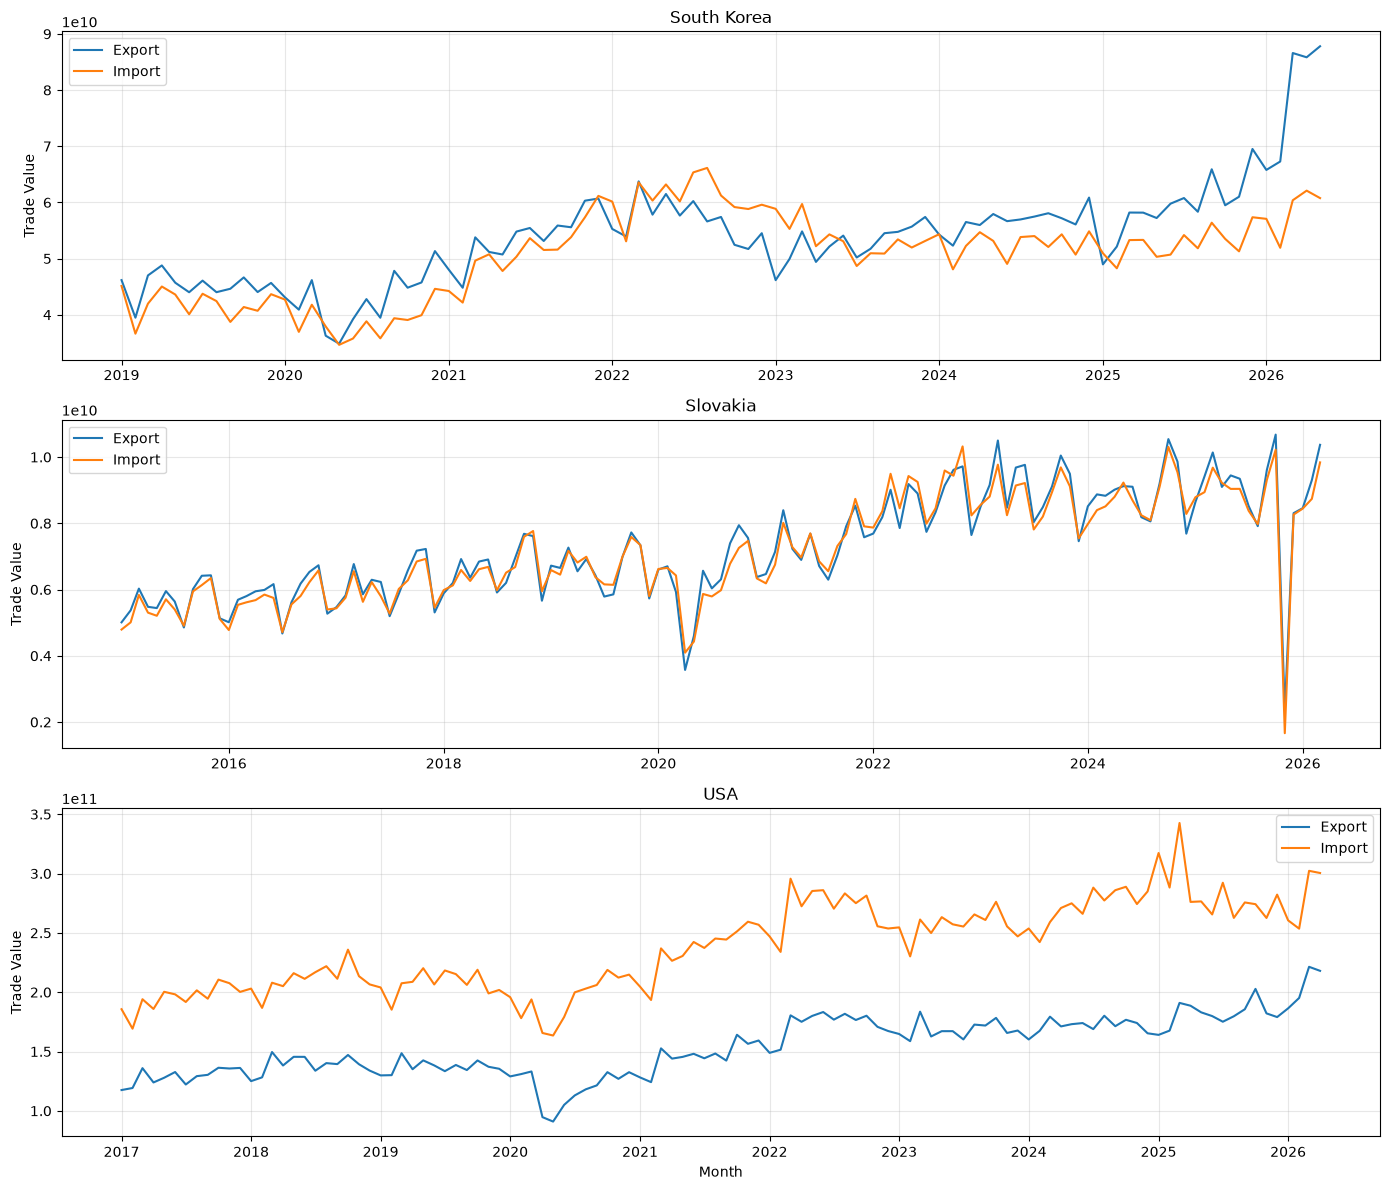

In [33]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

for ax, (country, path) in zip(axes, DATASETS.items()):
    file_path = path.as_posix().replace("'", "''")

    monthly = con.execute(f"""
        SELECT
            Month,
            TradeFlow,
            SUM(Value) AS TotalValue
        FROM read_parquet('{file_path}')
        GROUP BY Month, TradeFlow
        ORDER BY Month
    """).df()

    for flow in ["export", "import"]:
        flow_data = monthly[monthly["TradeFlow"] == flow]
        ax.plot(
            flow_data["Month"],
            flow_data["TotalValue"],
            label=flow.capitalize()
        )

    ax.set_title(country)
    ax.set_ylabel("Trade Value")
    ax.legend()
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Month")
plt.tight_layout()
plt.show()

### 4. Trade Flow Analysis

Compare aggregate export and import values across the three countries, examining their total values and monthly export-to-import ratios.

In [34]:
trade_flow_summary = []

for country, path in DATASETS.items():
    file_path = path.as_posix().replace("'", "''")

    summary = con.execute(f"""
        SELECT
            '{country}' AS Country,
            SUM(CASE WHEN TradeFlow = 'export' THEN Value ELSE 0 END)
                AS TotalExports,
            SUM(CASE WHEN TradeFlow = 'import' THEN Value ELSE 0 END)
                AS TotalImports
        FROM read_parquet('{file_path}')
    """).df()

    trade_flow_summary.append(summary)

trade_flow_summary = pd.concat(trade_flow_summary, ignore_index=True)

trade_flow_summary["ExportImportRatio"] = (
    trade_flow_summary["TotalExports"]
    / trade_flow_summary["TotalImports"].replace(0, np.nan)
)

display(trade_flow_summary)

,Country,TotalExports,TotalImports,ExportImportRatio
0,South Korea,4.795964e+12,4.512834e+12,1.062739
1,Slovakia,9.840019e+11,9.707650e+11,1.013636
2,USA,1.719905e+13,2.664245e+13,0.645551


### 5. Partner Country Analysis

Identify the main trading partners for each country by aggregating trade values across months and products, and visualize the top 10 partners separately for exports and imports.

South Korea — Top 10 partners by export


,Partner,TotalTradeValue
0,chn,1.054692e+12
1,usa,7.920010e+11
2,vnm,4.249419e+11
3,hkg,2.522055e+11
4,jpn,2.141121e+11
5,twn,2.126966e+11
6,ind,1.269971e+11
7,sgp,1.243454e+11
8,aus,9.961982e+10
9,mex,8.735128e+10


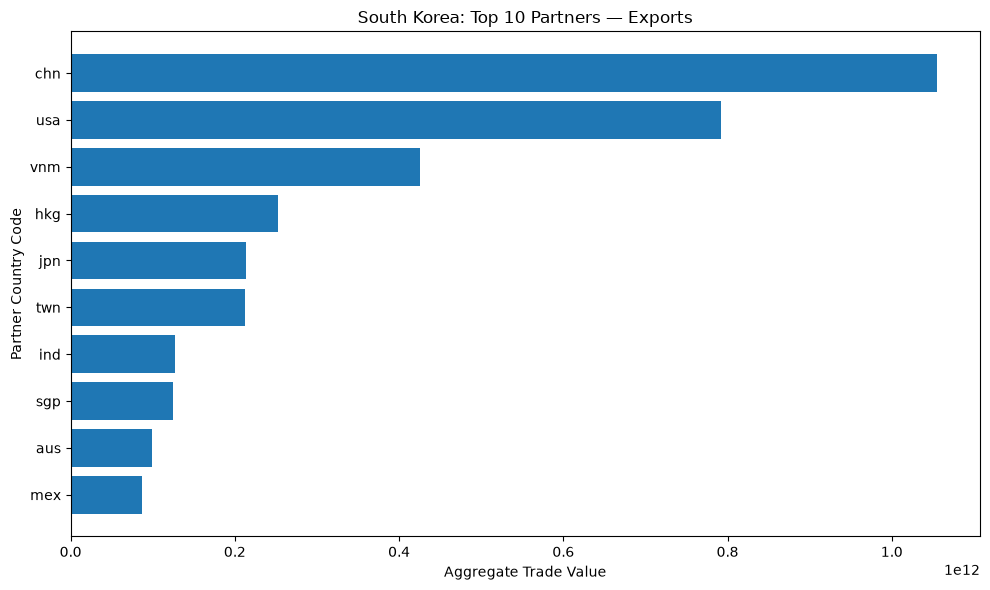

South Korea — Top 10 partners by import


,Partner,TotalTradeValue
0,chn,1.003202e+12
1,usa,5.263631e+11
2,jpn,3.688184e+11
3,aus,2.259938e+11
4,sau,2.055604e+11
5,vnm,1.931781e+11
6,twn,1.872770e+11
7,deu,1.627196e+11
8,mys,9.678543e+10
9,are,9.269235e+10


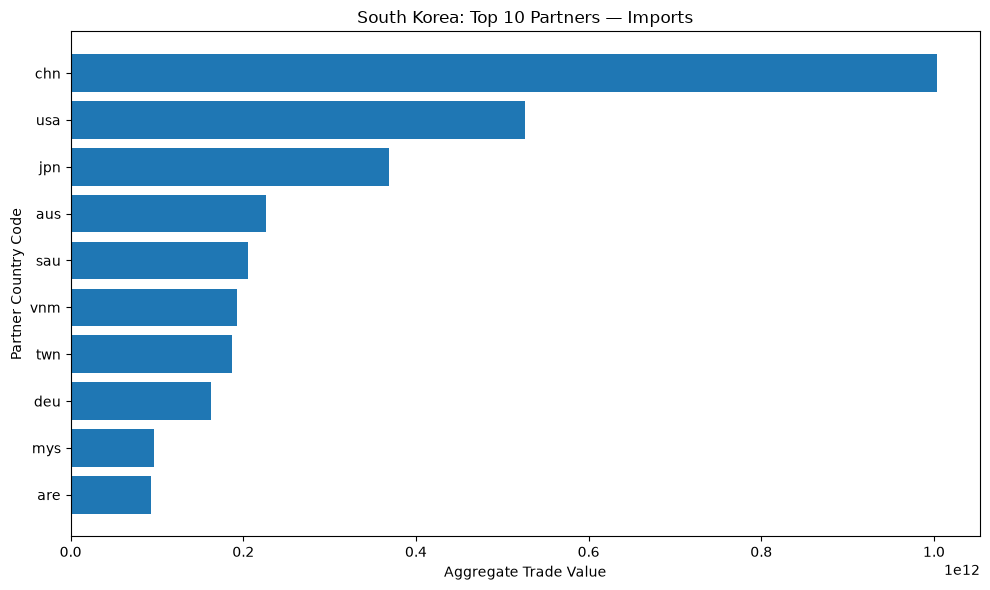

Slovakia — Top 10 partners by export


,Partner,TotalTradeValue
0,deu,2.120450e+11
1,cze,1.166808e+11
2,pol,7.657343e+10
3,hun,6.958928e+10
4,fra,5.731443e+10
5,aut,5.440024e+10
6,ita,4.676381e+10
7,gbr,4.460777e+10
8,usa,3.307376e+10
9,esp,2.495841e+10


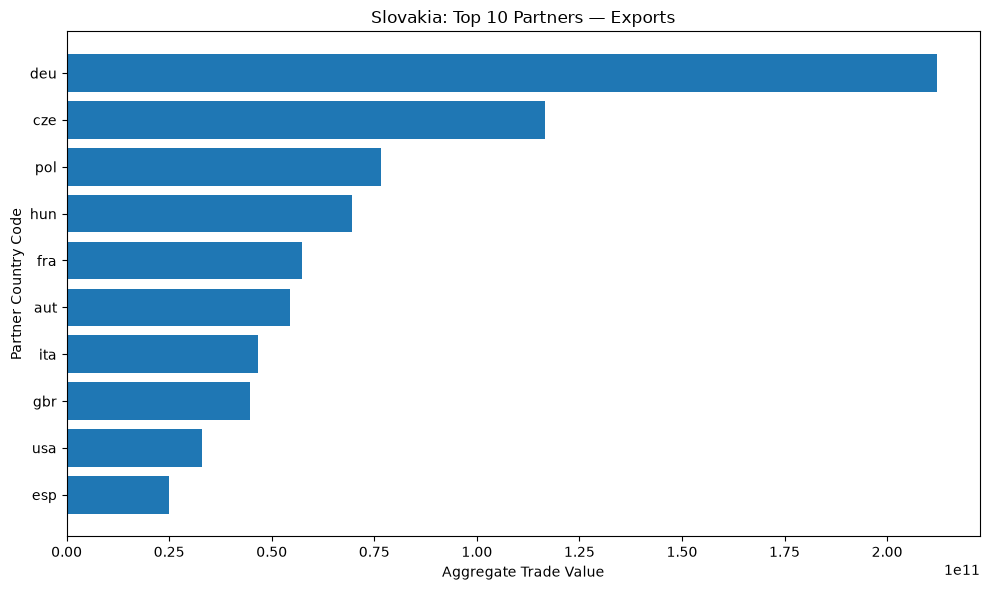

Slovakia — Top 10 partners by import


,Partner,TotalTradeValue
0,deu,1.851018e+11
1,cze,1.675337e+11
2,aut,8.314836e+10
3,pol,7.683742e+10
4,hun,6.445234e+10
5,rus,3.976985e+10
6,chn,3.906418e+10
7,kor,3.842369e+10
8,fra,3.570490e+10
9,ita,3.467349e+10


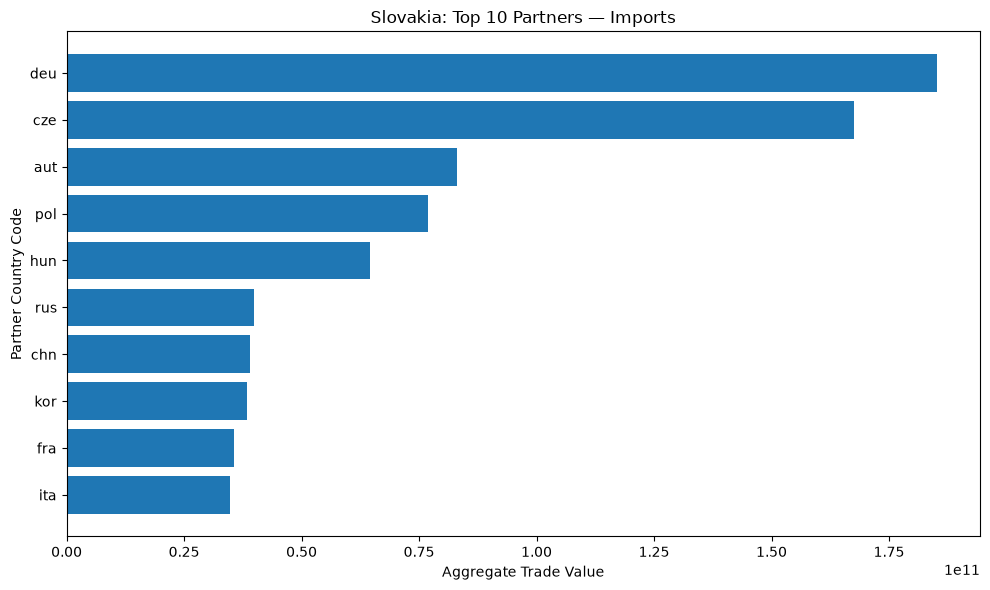

USA — Top 10 partners by export


,Partner,TotalTradeValue
0,can,2.948261e+12
1,mex,2.706193e+12
2,chn,1.220672e+12
3,jpn,7.021492e+11
4,gbr,6.847315e+11
5,deu,6.330531e+11
6,nld,6.139908e+11
7,kor,5.764437e+11
8,bra,4.208742e+11
9,fra,3.649989e+11


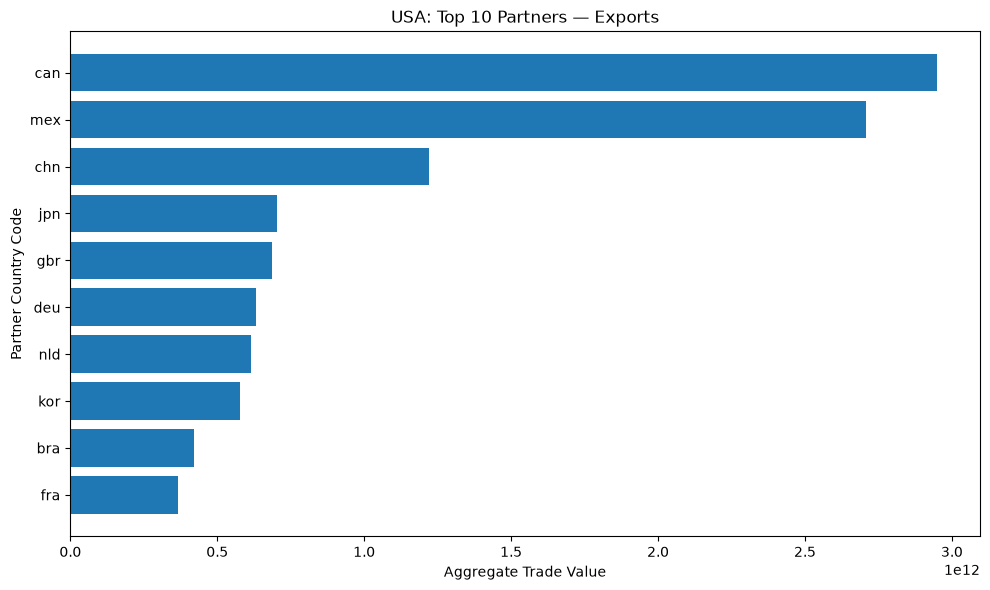

USA — Top 10 partners by import


,Partner,TotalTradeValue
0,chn,4.221039e+12
1,mex,3.872817e+12
2,can,3.340445e+12
3,jpn,1.313106e+12
4,deu,1.289991e+12
5,vnm,9.919753e+11
6,kor,9.321136e+11
7,twn,8.684932e+11
8,irl,7.282675e+11
9,ind,6.766738e+11


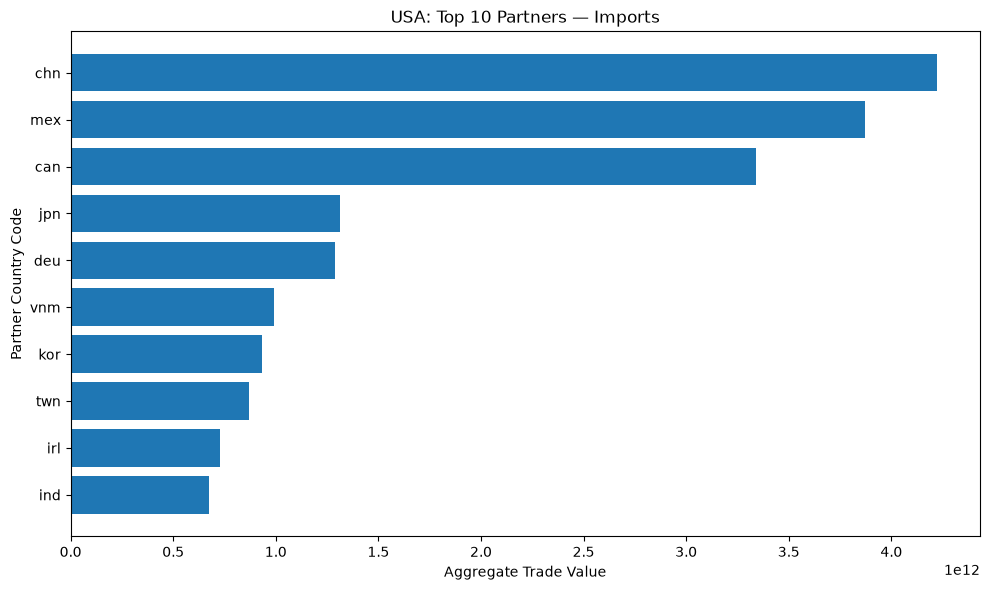

In [35]:
TOP_N = 10

for country, path in DATASETS.items():
    file_path = path.as_posix().replace("'", "''")

    for flow in ["export", "import"]:
        print(f"{country} — Top {TOP_N} partners by {flow}")

        top_partners = con.execute(f"""
            SELECT
                Country2 AS Partner,
                SUM(Value) AS TotalTradeValue
            FROM read_parquet('{file_path}')
            WHERE TradeFlow = '{flow}'
            GROUP BY Country2
            ORDER BY TotalTradeValue DESC
            LIMIT {TOP_N}
        """).df()

        display(top_partners)

        plot_data = top_partners.sort_values("TotalTradeValue")

        plt.figure(figsize=(10, 6))
        plt.barh(
            plot_data["Partner"],
            plot_data["TotalTradeValue"]
        )
        plt.title(f"{country}: Top {TOP_N} Partners — {flow.capitalize()}s")
        plt.xlabel("Aggregate Trade Value")
        plt.ylabel("Partner Country Code")
        plt.tight_layout()
        plt.show()

### 6. Temporal Patterns and Structural Changes

Examine monthly trade-value series for potential seasonality, unusual fluctuations, and changes in trend. Compare year-over-year growth and monthly patterns to identify features that may be relevant to forecasting.

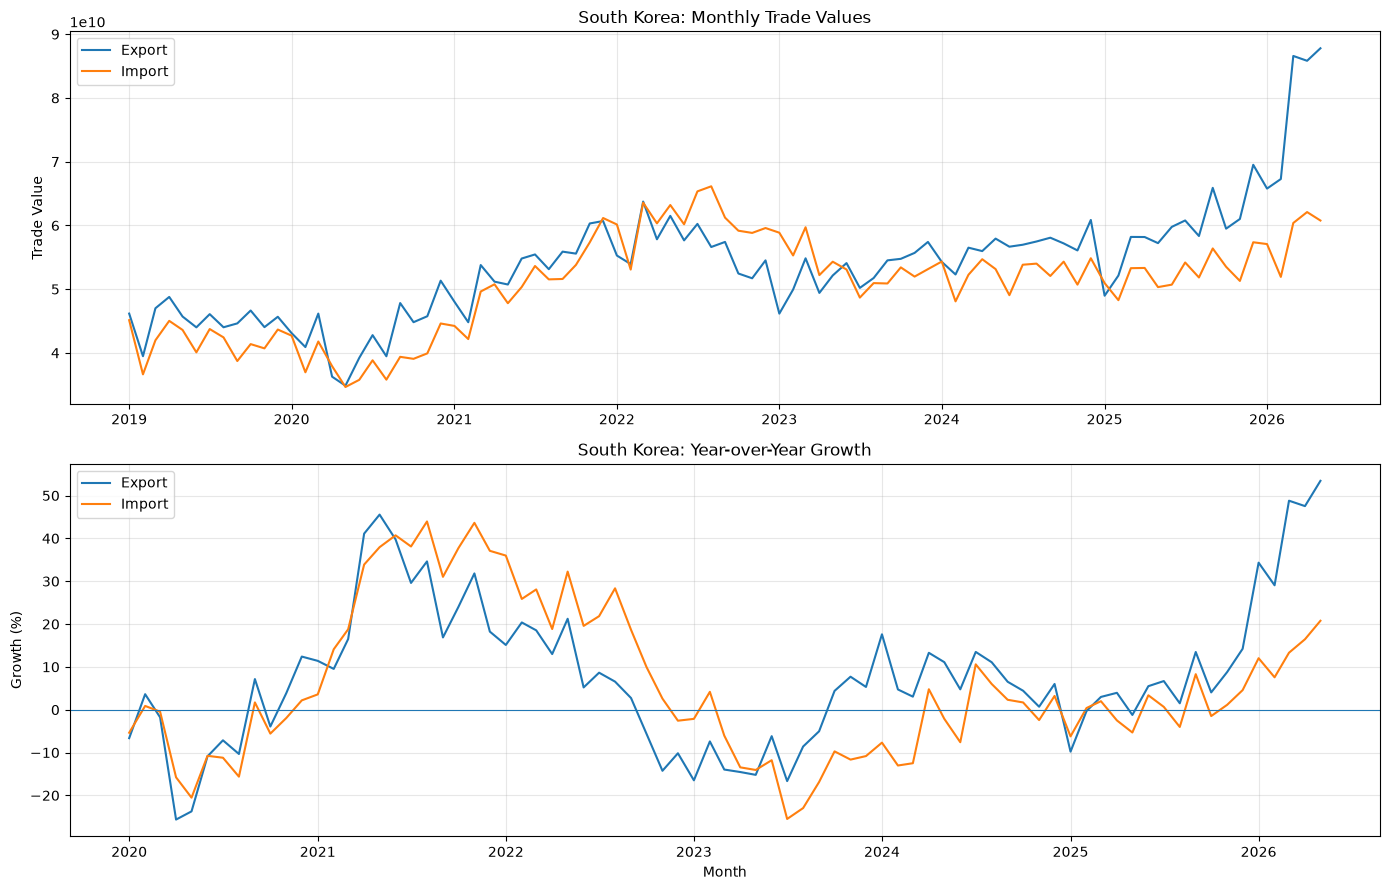

,CalendarMonth,TradeFlow,TotalValue
0,1,export,5.097069e+10
1,1,import,5.167902e+10
2,2,export,5.009980e+10
3,2,import,4.654988e+10
4,3,export,5.835427e+10
5,3,import,5.282522e+10
6,4,export,5.543122e+10
7,4,import,5.204474e+10
8,5,export,5.598515e+10
9,5,import,5.097346e+10


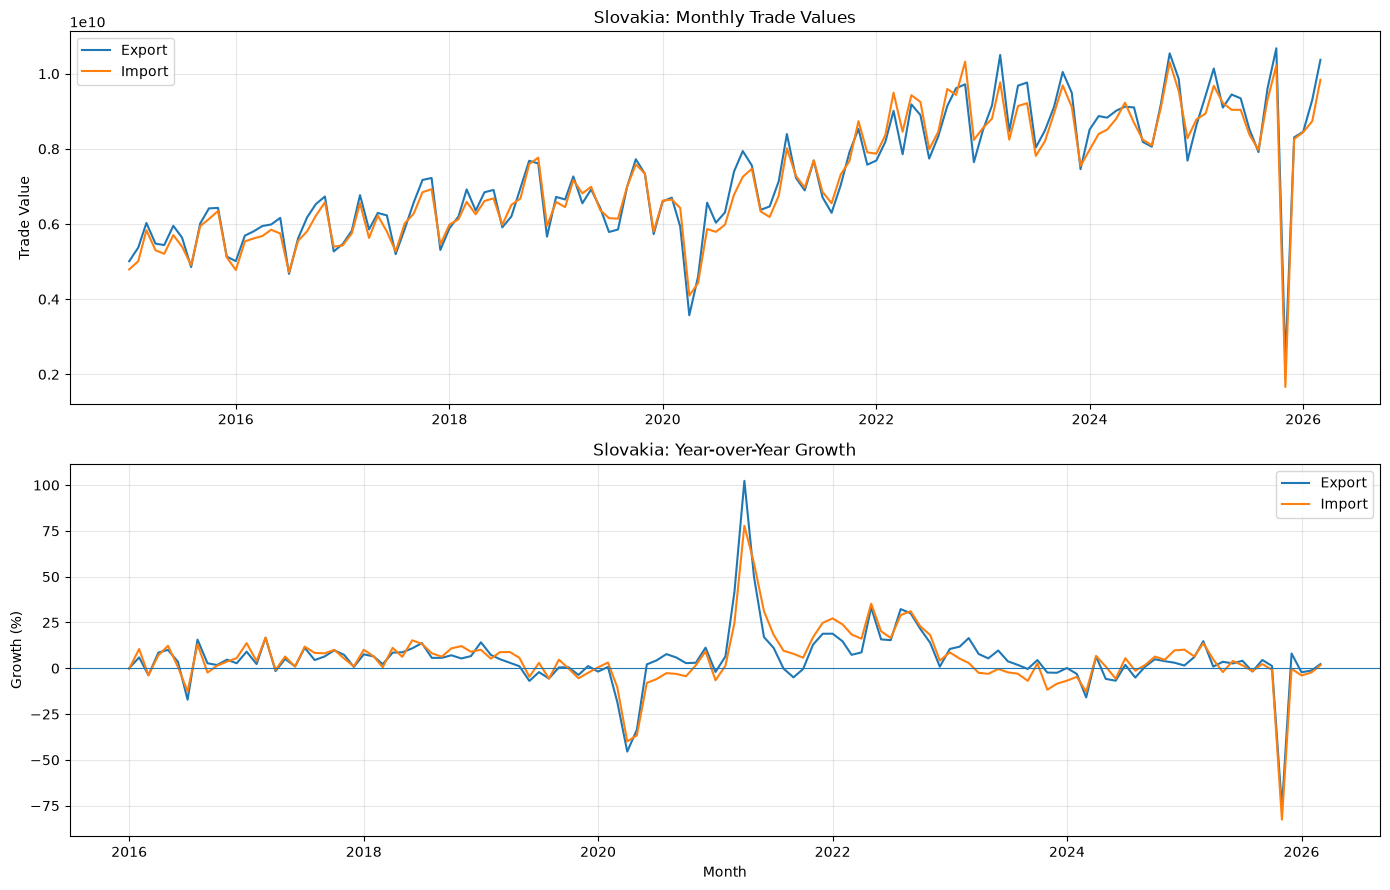

,CalendarMonth,TradeFlow,TotalValue
0,1,export,6.913911e+09
1,1,import,6.834518e+09
2,2,export,7.376368e+09
3,2,import,7.127340e+09
4,3,export,7.996305e+09
5,3,import,7.791734e+09
6,4,export,6.857277e+09
7,4,import,6.889304e+09
8,5,export,7.310967e+09
9,5,import,7.192669e+09


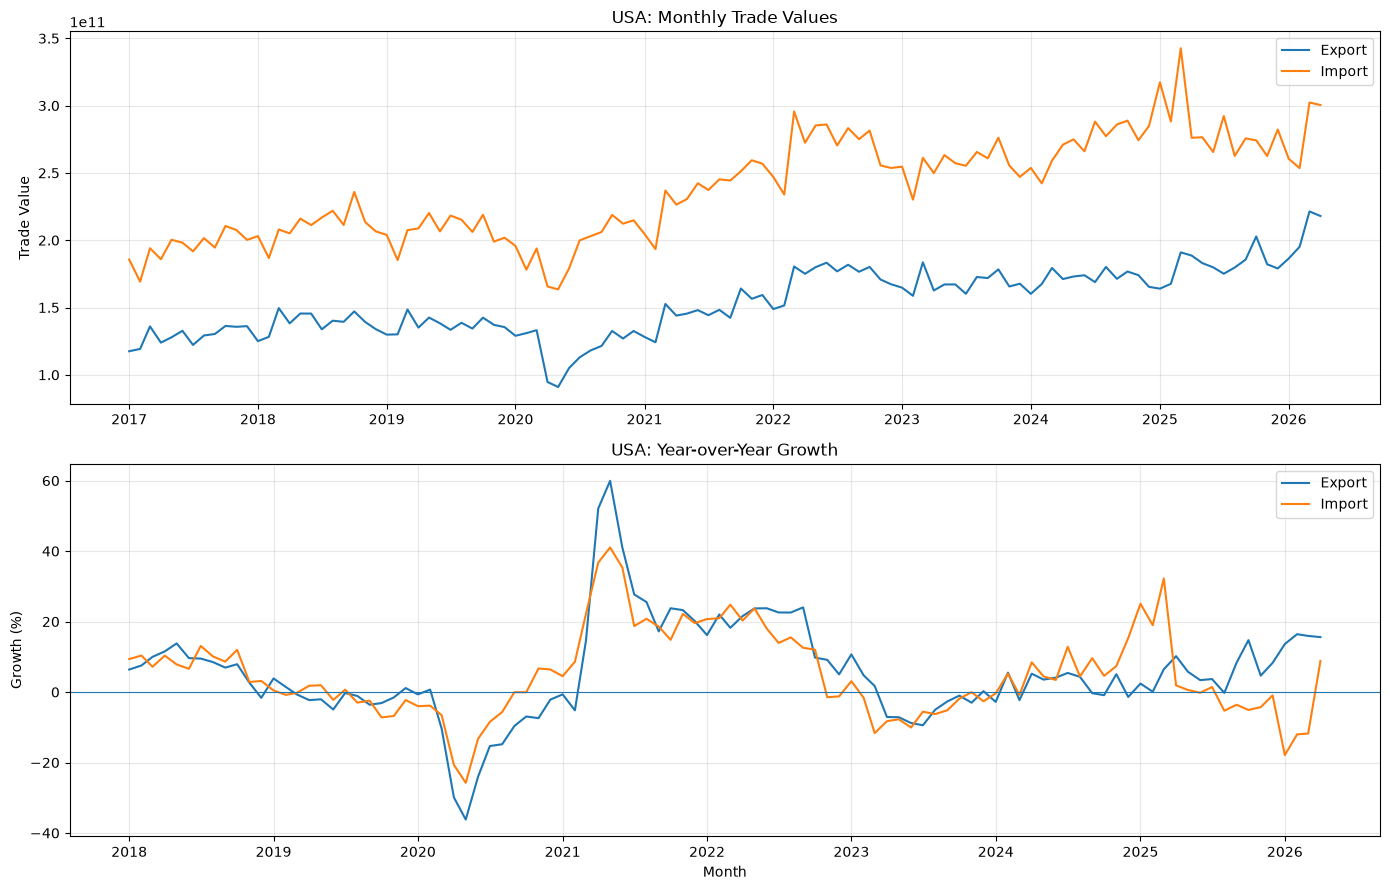

,CalendarMonth,TradeFlow,TotalValue
0,1,export,1.453813e+11
1,1,import,2.326272e+11
2,2,export,1.473146e+11
3,2,import,2.160928e+11
4,3,export,1.675711e+11
5,3,import,2.501256e+11
6,4,export,1.551403e+11
7,4,import,2.361571e+11
8,5,export,1.506194e+11
9,5,import,2.367288e+11


In [36]:
for country, path in DATASETS.items():
    file_path = path.as_posix().replace("'", "''")

    monthly = con.execute(f"""
        SELECT
            Month,
            TradeFlow,
            SUM(Value) AS TotalValue
        FROM read_parquet('{file_path}')
        GROUP BY Month, TradeFlow
        ORDER BY Month
    """).df()

    monthly["Month"] = pd.to_datetime(monthly["Month"])
    monthly["Year"] = monthly["Month"].dt.year
    monthly["CalendarMonth"] = monthly["Month"].dt.month

    # Year-over-year growth, calculated separately for each trade flow.
    monthly["YoYGrowthPct"] = (
        monthly.groupby("TradeFlow")["TotalValue"]
        .pct_change(periods=12) * 100
    )

    fig, axes = plt.subplots(2, 1, figsize=(14, 9))

    for flow in ["export", "import"]:
        flow_data = monthly[monthly["TradeFlow"] == flow]

        axes[0].plot(
            flow_data["Month"],
            flow_data["TotalValue"],
            label=flow.capitalize()
        )
        axes[1].plot(
            flow_data["Month"],
            flow_data["YoYGrowthPct"],
            label=flow.capitalize()
        )

    axes[0].set_title(f"{country}: Monthly Trade Values")
    axes[0].set_ylabel("Trade Value")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].set_title(f"{country}: Year-over-Year Growth")
    axes[1].set_ylabel("Growth (%)")
    axes[1].set_xlabel("Month")
    axes[1].axhline(0, linewidth=0.8)
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Average monthly trade value by calendar month.
    seasonal = (
        monthly.groupby(["CalendarMonth", "TradeFlow"])["TotalValue"]
        .mean()
        .reset_index()
    )

    display(seasonal)

 ## 7. Assess time-series suitability
 
 Examine the number of observations, historical coverage, and missing months for individual product–partner–trade-flow series.

### 7.1 Inspect Product-Level Time-Series Coverage

Measure the number of observations, historical span, and monthly coverage of each product–partner–trade-flow series. This will help identify sparse or incomplete series before selecting candidates for forecasting.

In [38]:
from pathlib import Path

# Resolve processed dataset paths from the project root
project_root = Path.cwd().parent

datasets = {
    "South Korea": project_root / "Data" / "processed" / "korea_trade_monthly.parquet",
    "Slovakia": project_root / "Data" / "processed" / "slovakia_trade_monthly.parquet",
    "USA": project_root / "Data" / "processed" / "usa_trade_aggregated.parquet",
}

con = duckdb.connect()
coverage_results = []

for country, path in datasets.items():
    if not path.exists():
        raise FileNotFoundError(f"{country} dataset not found: {path}")

    query = """
        SELECT
            Country1,
            Country2,
            ProductCode,
            TradeFlow,
            COUNT(*) AS n_observations,
            MIN(Month) AS first_month,
            MAX(Month) AS last_month,
            DATE_DIFF('month', MIN(Month), MAX(Month)) + 1
                AS expected_months
        FROM read_parquet(?)
        GROUP BY Country1, Country2, ProductCode, TradeFlow
    """

    series = con.execute(query, [str(path)]).df()
    series["country_dataset"] = country
    series["coverage_rate"] = (
        series["n_observations"] / series["expected_months"]
    )
    series["missing_months"] = (
        series["expected_months"] - series["n_observations"]
    )

    coverage_results.append(series)

coverage = pd.concat(coverage_results, ignore_index=True)

summary = (
    coverage.groupby("country_dataset")
    .agg(
        n_series=("ProductCode", "size"),
        median_observations=("n_observations", "median"),
        min_observations=("n_observations", "min"),
        median_coverage=("coverage_rate", "median"),
        fully_covered_series=("missing_months", lambda x: (x == 0).sum()),
        series_with_gaps=("missing_months", lambda x: (x > 0).sum()),
    )
    .reset_index()
)

summary["median_coverage"] = (summary["median_coverage"] * 100).round(2)

display(summary)

,country_dataset,n_series,median_observations,min_observations,median_coverage,fully_covered_series,series_with_gaps
0,Slovakia,113327,13.0,1,52.48,23762,89565
1,South Korea,235386,14.0,1,55.17,73142,162244
2,USA,256699,57.0,1,92.79,95307,161392


### 7.2 Identify Series with Sufficient History

Count the product–partner–trade-flow series that meet a minimum history requirement of 36 monthly observations in each country. This initial filter assesses feasibility; gap handling and final eligibility will be evaluated separately.

In [39]:
MIN_OBSERVATIONS = 36

eligibility_summary = (
    coverage.assign(
        sufficient_history=coverage["n_observations"] >= MIN_OBSERVATIONS
    )
    .groupby("country_dataset")
    .agg(
        total_series=("ProductCode", "size"),
        eligible_series=("sufficient_history", "sum"),
    )
    .reset_index()
)

eligibility_summary["eligible_pct"] = (
    100 * eligibility_summary["eligible_series"]
    / eligibility_summary["total_series"]
).round(2)

display(eligibility_summary)

,country_dataset,total_series,eligible_series,eligible_pct
0,Slovakia,113327,41270,36.42
1,South Korea,235386,85578,36.36
2,USA,256699,154829,60.32


### 7.3 Assess Monthly Gaps in Eligible Series

For series with at least 36 observations, summarize missing months between the first and last recorded observations. This distinguishes series with consistent monthly histories from those requiring further investigation.

In [40]:
eligible = coverage.loc[
    coverage["n_observations"] >= MIN_OBSERVATIONS
].copy()

gap_summary = (
    eligible.assign(has_gaps=eligible["missing_months"] > 0)
    .groupby("country_dataset")
    .agg(
        eligible_series=("ProductCode", "size"),
        fully_covered_series=("has_gaps", lambda x: (~x).sum()),
        series_with_gaps=("has_gaps", "sum"),
        median_coverage=("coverage_rate", "median"),
        median_missing_months=("missing_months", "median"),
    )
    .reset_index()
)

gap_summary["fully_covered_pct"] = (
    100 * gap_summary["fully_covered_series"]
    / gap_summary["eligible_series"]
).round(2)

gap_summary["median_coverage"] = (
    100 * gap_summary["median_coverage"]
).round(2)

display(gap_summary)

,country_dataset,eligible_series,fully_covered_series,series_with_gaps,median_coverage,median_missing_months,fully_covered_pct
0,Slovakia,41270,1996,39274,83.46,20.0,4.84
1,South Korea,85578,33160,52418,95.40,4.0,38.75
2,USA,154829,48728,106101,93.75,7.0,31.47


### 7.4 Examine the Distribution of Missing Months

Summarize the proportion of missing months among eligible series to determine whether gaps are generally limited or substantial. This will inform the series-selection and preprocessing strategy.

In [41]:
gap_distribution = (
    eligible.assign(
        coverage_band=pd.cut(
            eligible["coverage_rate"],
            bins=[0, 0.5, 0.75, 0.9, 0.99, 1.0],
            labels=[
                "≤50%",
                "50–75%",
                "75–90%",
                "90–99%",
                "100%",
            ],
            include_lowest=True,
        )
    )
    .groupby(
        ["country_dataset", "coverage_band"],
        observed=False,
    )
    .size()
    .rename("n_series")
    .reset_index()
)

gap_distribution["pct_series"] = (
    gap_distribution["n_series"]
    / gap_distribution.groupby("country_dataset")["n_series"].transform("sum")
    * 100
).round(2)

display(gap_distribution)

,country_dataset,coverage_band,n_series,pct_series
0,Slovakia,≤50%,8174,19.81
1,Slovakia,50–75%,9185,22.26
2,Slovakia,75–90%,6071,14.71
3,Slovakia,90–99%,6589,15.97
4,Slovakia,100%,11251,27.26
5,South Korea,≤50%,6892,8.05
6,South Korea,50–75%,18326,21.41
7,South Korea,75–90%,12410,14.50
8,South Korea,90–99%,14790,17.28
9,South Korea,100%,33160,38.75


### 7.5 Inspect Missing-Month Patterns in Individual Series

Select representative product–partner–trade-flow series with missing months and compare their expected monthly calendars with their recorded observations. This inspection helps characterize the gaps before deciding how to handle them.

In [42]:

from pathlib import Path
import duckdb
import pandas as pd
import seaborn as sns

MIN_OBSERVATIONS = 36
con = duckdb.connect()
gap_location_results = []

for country, path in datasets.items():
    query = """
        WITH series AS (
            SELECT
                Country1, Country2, ProductCode, TradeFlow,
                MIN(Month) AS first_month,
                MAX(Month) AS last_month,
                COUNT(*) AS n_observations
            FROM read_parquet(?)
            GROUP BY Country1, Country2, ProductCode, TradeFlow
            HAVING COUNT(*) >= ?
        ),
        expected_months AS (
            SELECT
                s.Country1, s.Country2, s.ProductCode, s.TradeFlow,
                s.first_month, s.last_month, s.n_observations,
                m.month_start
            FROM series s
            CROSS JOIN LATERAL generate_series(
                s.first_month,
                s.last_month,
                INTERVAL 1 MONTH
            ) AS m(month_start)
        )
        SELECT
            e.Country1, e.Country2, e.ProductCode, e.TradeFlow,
            e.first_month, e.last_month, e.n_observations,
            COUNT(*) FILTER (
                WHERE d.Month IS NULL
            ) AS missing_months,
            MIN(d.Month) AS first_recorded_month
        FROM expected_months e
        LEFT JOIN read_parquet(?) d
          ON d.Country1 = e.Country1
         AND d.Country2 = e.Country2
         AND d.ProductCode = e.ProductCode
         AND d.TradeFlow = e.TradeFlow
         AND d.Month = e.month_start
        GROUP BY
            e.Country1, e.Country2, e.ProductCode, e.TradeFlow,
            e.first_month, e.last_month, e.n_observations
    """

    # Generate each series' expected monthly calendar and find absent months.
    series_gaps = con.execute(
        query, [str(path), MIN_OBSERVATIONS, str(path)]
    ).df()
    series_gaps["country_dataset"] = country
    gap_location_results.append(series_gaps)

gap_location = pd.concat(gap_location_results, ignore_index=True)

display(
    gap_location.groupby("country_dataset")
    .agg(
        eligible_series=("ProductCode", "size"),
        series_with_internal_gaps=("missing_months", lambda x: (x > 0).sum()),
        median_missing_months=("missing_months", "median"),
        max_missing_months=("missing_months", "max"),
    )
    .reset_index()
)


# Select a series with many missing months from each country.
# The selection is for inspection only, not final model selection.

sample_series = (
    gap_location.sort_values(
        ["country_dataset", "missing_months"],
        ascending=[True, False],
    )
    .groupby("country_dataset")
    .head(2)[
        [
            "country_dataset", "Country1", "Country2",
            "ProductCode", "TradeFlow", "first_month",
            "last_month", "n_observations", "missing_months",
        ]
    ]
)

display(sample_series)


,country_dataset,eligible_series,series_with_internal_gaps,median_missing_months,max_missing_months
0,Slovakia,41270,39274,20.0,99
1,South Korea,85578,52418,4.0,53
2,USA,154829,106101,7.0,76


,country_dataset,Country1,Country2,ProductCode,TradeFlow,first_month,last_month,n_observations,missing_months
87128,Slovakia,SVK,lva,7204,export,2015-01-01,2026-03-01,36,99
87536,Slovakia,SVK,hrv,4410,export,2015-01-01,2026-03-01,36,99
278,South Korea,KOR,fin,8214,import,2019-01-01,2026-05-01,36,53
575,South Korea,KOR,are,7409,export,2019-01-01,2026-05-01,36,53
129158,USA,USA,ven,3920,import,2017-01-01,2026-04-01,36,76
133223,USA,USA,dnk,3812,import,2017-01-01,2026-04-01,36,76


### 7.6 Inspect Monthly Observation Patterns

For the selected series, generate the complete monthly calendar between the first and last recorded observations and mark each month as recorded or absent. This will reveal the timing and continuity of gaps.

In [43]:

monthly_patterns = []

for _, series in sample_series.iterrows():
    country = series["country_dataset"]
    path = datasets[country]

    query = """
        WITH calendar AS (
            SELECT month_start
            FROM generate_series(
                CAST(? AS DATE),
                CAST(? AS DATE),
                INTERVAL 1 MONTH
            ) AS t(month_start)
        )
        SELECT
            month_start AS Month,
            CASE WHEN d.Month IS NULL THEN 0 ELSE 1 END AS recorded
        FROM calendar c
        LEFT JOIN read_parquet(?) d
          ON d.Month = c.month_start
         AND d.Country1 = ?
         AND d.Country2 = ?
         AND d.ProductCode = ?
         AND d.TradeFlow = ?
        ORDER BY Month
    """

    pattern = con.execute(
        query,
        [
            series["first_month"],
            series["last_month"],
            str(path),
            series["Country1"],
            series["Country2"],
            series["ProductCode"],
            series["TradeFlow"],
        ],
    ).df()

    pattern["country_dataset"] = country
    pattern["Country2"] = series["Country2"]
    pattern["ProductCode"] = series["ProductCode"]
    pattern["TradeFlow"] = series["TradeFlow"]
    monthly_patterns.append(pattern)

monthly_patterns = pd.concat(monthly_patterns, ignore_index=True)

display(monthly_patterns)


,Month,recorded,country_dataset,Country2,ProductCode,TradeFlow
0,2015-01-01,1,Slovakia,lva,7204,export
1,2015-02-01,1,Slovakia,lva,7204,export
2,2015-03-01,0,Slovakia,lva,7204,export
3,2015-04-01,0,Slovakia,lva,7204,export
4,2015-05-01,0,Slovakia,lva,7204,export
...,...,...,...,...,...,...
667,2025-12-01,0,USA,dnk,3812,import
668,2026-01-01,0,USA,dnk,3812,import
669,2026-02-01,0,USA,dnk,3812,import
670,2026-03-01,0,USA,dnk,3812,import


### 7.7 Visualize Missing Months and Series Boundaries

Plot a reproducible sample of 20 product–partner–trade-flow series per country across the country's full reporting period. Distinguish recorded observations, missing months within each series' observed span, and months outside that span.

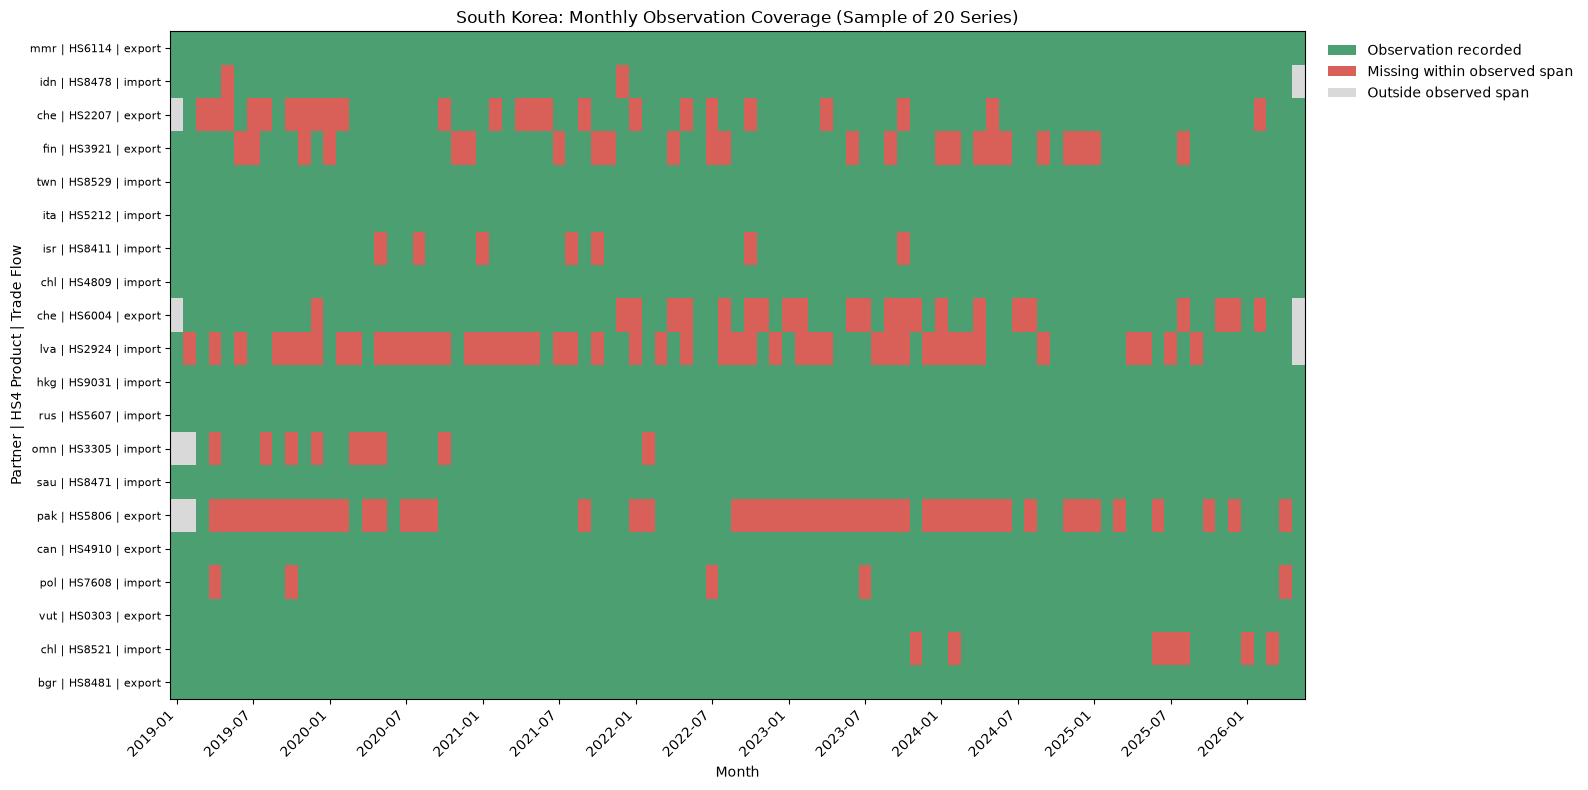

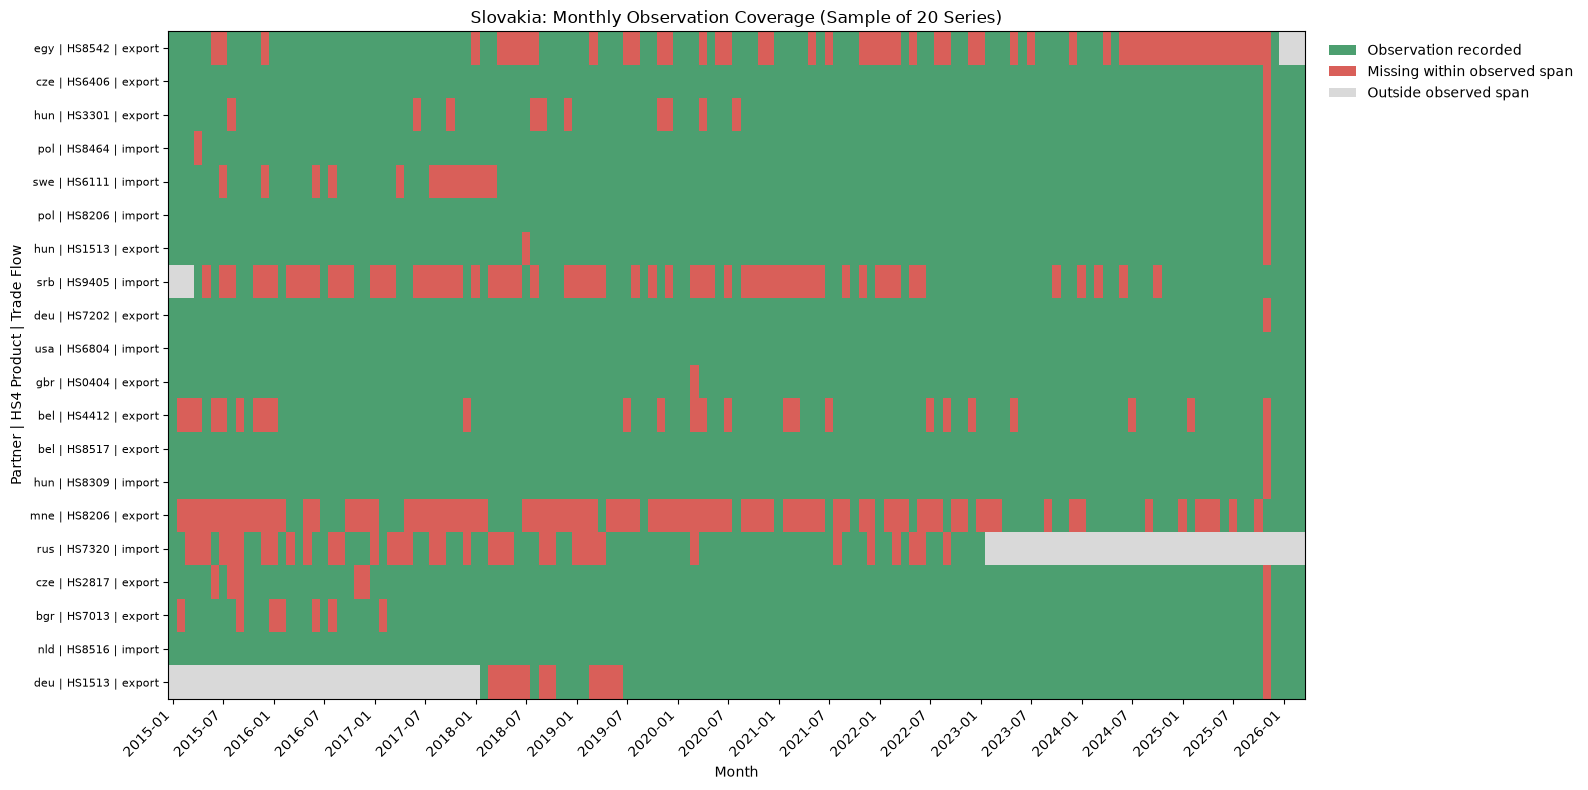

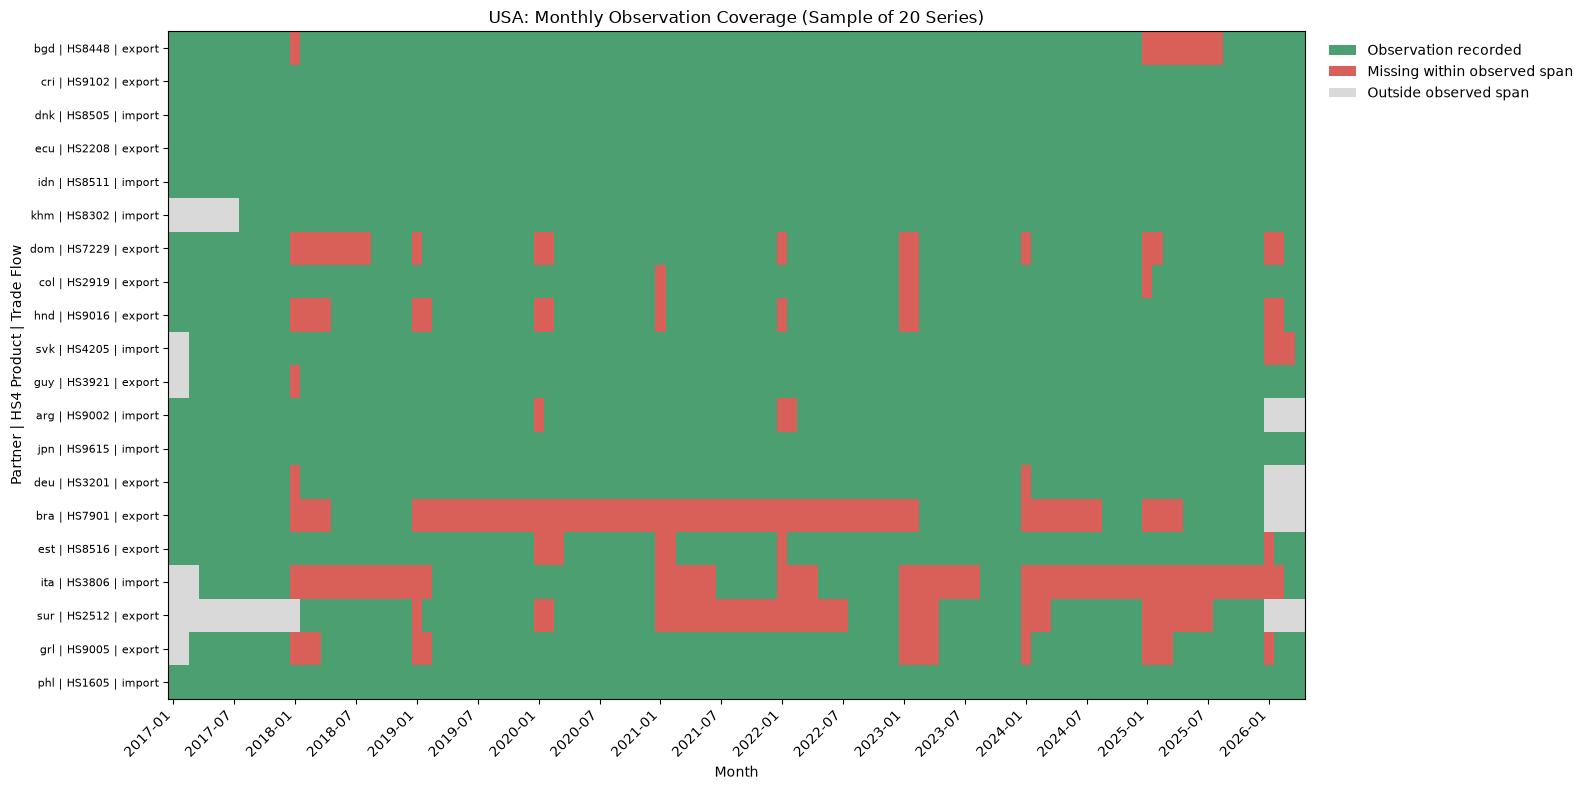

In [44]:
MIN_OBSERVATIONS = 36
SAMPLE_SIZE = 20
con = duckdb.connect()

# 0 = outside series span, 1 = missing within span, 2 = recorded
cmap = ListedColormap(["#D9D9D9", "#D95F59", "#4C9F70"])
norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], cmap.N)

for country, path in DATASETS.items():
    # Full monthly calendar for this country's dataset.
    bounds = con.execute("""
        SELECT MIN(Month), MAX(Month)
        FROM read_parquet(?)
    """, [str(path)]).fetchone()

    full_calendar = pd.date_range(
        pd.Timestamp(bounds[0]),
        pd.Timestamp(bounds[1]),
        freq="MS"
    )

    # Reproducibly sample series with at least 36 recorded observations.
    series = con.execute("""
        SELECT
            Country1, Country2, ProductCode, TradeFlow,
            MIN(Month) AS first_month,
            MAX(Month) AS last_month,
            COUNT(*) AS n_observations
        FROM read_parquet(?)
        GROUP BY Country1, Country2, ProductCode, TradeFlow
        HAVING COUNT(*) >= ?
        ORDER BY hash(Country1, Country2, ProductCode, TradeFlow)
        LIMIT ?
    """, [str(path), MIN_OBSERVATIONS, SAMPLE_SIZE]).df()

    heatmap_rows = []
    labels = []

    for _, s in series.iterrows():
        observed = con.execute("""
            SELECT Month
            FROM read_parquet(?)
            WHERE Country1 = ?
              AND Country2 = ?
              AND ProductCode = ?
              AND TradeFlow = ?
        """, [
            str(path), s["Country1"], s["Country2"],
            s["ProductCode"], s["TradeFlow"]
        ]).df()["Month"]

        observed_months = set(
            pd.to_datetime(observed).dt.to_period("M")
        )
        first = pd.Timestamp(s["first_month"]).to_period("M")
        last = pd.Timestamp(s["last_month"]).to_period("M")

        row = []
        for month in full_calendar:
            period = month.to_period("M")
            if period < first or period > last:
                row.append(0)  # Outside observed span
            elif period in observed_months:
                row.append(2)  # Recorded
            else:
                row.append(1)  # Missing within observed span

        heatmap_rows.append(row)
        labels.append(
            f'{s["Country2"]} | HS{s["ProductCode"]} | {s["TradeFlow"]}'
        )

    fig, ax = plt.subplots(figsize=(16, 8))
    ax.imshow(
        heatmap_rows,
        aspect="auto",
        interpolation="nearest",
        cmap=cmap,
        norm=norm
    )

    # Label a manageable number of dates on the x-axis.
    tick_positions = list(range(0, len(full_calendar), 6))
    ax.set_xticks(tick_positions)
    ax.set_xticklabels(
        [full_calendar[i].strftime("%Y-%m") for i in tick_positions],
        rotation=45,
        ha="right"
    )

    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel("Month")
    ax.set_ylabel("Partner | HS4 Product | Trade Flow")
    ax.set_title(
        f"{country}: Monthly Observation Coverage "
        f"(Sample of {len(series)} Series)"
    )

    legend_items = [
        Patch(facecolor="#4C9F70", label="Observation recorded"),
        Patch(facecolor="#D95F59", label="Missing within observed span"),
        Patch(facecolor="#D9D9D9", label="Outside observed span"),
    ]
    ax.legend(handles=legend_items, loc="upper left",
              bbox_to_anchor=(1.01, 1), frameon=False)

    plt.tight_layout()
    plt.show()


### 7.8 Check indidual samples

In [ ]:
import duckdb

con = duckdb.connect()

for country, path in DATASETS.items():
    file_path = path.as_posix().replace("'", "''")

    examples = con.execute(f"""
        WITH ordered AS (
            SELECT
                Country1, Country2, ProductCode, TradeFlow,
                Month,
                LAG(Month) OVER (
                    PARTITION BY Country1, Country2,
                                 ProductCode, TradeFlow
                    ORDER BY Month
                ) AS previous_month
            FROM read_parquet('{file_path}')
        )
        SELECT
            Country1, Country2, ProductCode, TradeFlow,
            previous_month,
            previous_month + INTERVAL '1 month' AS missing_month,
            Month AS next_observed_month
        FROM ordered
        WHERE previous_month IS NOT NULL
          AND date_diff('month', previous_month, Month) > 1
        ORDER BY missing_month
        LIMIT 10
    """).df()

    print(f"\\n{country}")
    display(examples)


\nSouth Korea


,Country1,Country2,ProductCode,TradeFlow,previous_month,missing_month,next_observed_month
0,KOR,ago,8468,export,2019-01-01,2019-02-01,2022-06-01
1,KOR,alb,9506,export,2019-01-01,2019-02-01,2020-11-01
2,KOR,are,0802,import,2019-01-01,2019-02-01,2019-04-01
3,KOR,ago,8202,import,2019-01-01,2019-02-01,2026-04-01
4,KOR,are,2837,import,2019-01-01,2019-02-01,2019-06-01
5,KOR,afg,6301,export,2019-01-01,2019-02-01,2019-10-01
6,KOR,are,2903,export,2019-01-01,2019-02-01,2019-03-01
7,KOR,alb,1604,import,2019-01-01,2019-02-01,2019-03-01
8,KOR,are,0910,export,2019-01-01,2019-02-01,2019-05-01
9,KOR,are,3206,export,2019-01-01,2019-02-01,2019-03-01


\nSlovakia


,Country1,Country2,ProductCode,TradeFlow,previous_month,missing_month,next_observed_month
0,SVK,bgr,3401,import,2015-01-01,2015-02-01,2015-03-01
1,SVK,chn,8454,import,2015-01-01,2015-02-01,2015-06-01
2,SVK,blr,3215,export,2015-01-01,2015-02-01,2017-05-01
3,SVK,cze,7508,export,2015-01-01,2015-02-01,2016-04-01
4,SVK,can,8525,import,2015-01-01,2015-02-01,2015-03-01
5,SVK,che,6815,import,2015-01-01,2015-02-01,2015-03-01
6,SVK,che,3211,import,2015-01-01,2015-02-01,2016-10-01
7,SVK,cyp,8421,export,2015-01-01,2015-02-01,2015-06-01
8,SVK,deu,0403,export,2015-01-01,2015-02-01,2015-03-01
9,SVK,gbr,2807,export,2015-01-01,2015-02-01,2015-03-01


\nUSA


,Country1,Country2,ProductCode,TradeFlow,previous_month,missing_month,next_observed_month
0,USA,aia,3822,export,2017-12-01,2018-01-01,2018-02-01
1,USA,aia,3306,export,2017-12-01,2018-01-01,2018-05-01
2,USA,aia,7013,export,2017-12-01,2018-01-01,2018-10-01
3,USA,ago,7226,export,2017-12-01,2018-01-01,2022-04-01
4,USA,alb,4009,export,2017-12-01,2018-01-01,2018-12-01
5,USA,afg,7907,export,2017-12-01,2018-01-01,2018-09-01
6,USA,are,0308,export,2017-12-01,2018-01-01,2023-01-01
7,USA,abw,7415,export,2017-12-01,2018-01-01,2018-09-01
8,USA,aia,8714,export,2017-12-01,2018-01-01,2018-07-01
9,USA,are,2804,import,2017-12-01,2018-01-01,2019-01-01


### 7.9 Fill Missing Months with Zero

Complete each product-level bilateral trade series by inserting missing months between its first and last observed months and assigning `Value = 0`. Save the completed datasets separately so the original processed data remain unchanged.

In [ ]:
# Create completed monthly datasets without modifying the originals.
COMPLETED_DATA_DIR = PROJECT_DIR / "Data" / "processed_monthly_complete"
COMPLETED_DATA_DIR.mkdir(parents=True, exist_ok=True)

completed_datasets = {
    "South Korea": COMPLETED_DATA_DIR / "korea_trade_monthly_complete.parquet",
    "Slovakia": COMPLETED_DATA_DIR / "slovakia_trade_monthly_complete.parquet",
    "USA": COMPLETED_DATA_DIR / "usa_trade_monthly_complete.parquet",
}

con = duckdb.connect()

for country, input_path in DATASETS.items():
    output_path = completed_datasets[country]
    input_file = input_path.as_posix().replace("'", "''")
    output_file = output_path.as_posix().replace("'", "''")

    con.execute(f"""
        COPY (
            WITH original AS (
                SELECT *
                FROM read_parquet('{input_file}')
            ),
            series_bounds AS (
                SELECT
                    Country1,
                    Country2,
                    ProductCode,
                    TradeFlow,
                    MIN(Month) AS first_month,
                    MAX(Month) AS last_month
                FROM original
                GROUP BY
                    Country1, Country2, ProductCode, TradeFlow
            ),
            monthly_calendar AS (
                SELECT
                    s.Country1,
                    s.Country2,
                    s.ProductCode,
                    s.TradeFlow,
                    m.Month
                FROM series_bounds s
                CROSS JOIN LATERAL generate_series(
                    s.first_month,
                    s.last_month,
                    INTERVAL 1 MONTH
                ) AS m(Month)
            )
            SELECT
                c.Month,
                c.Country1,
                c.Country2,
                c.ProductCode,
                c.TradeFlow,
                COALESCE(o.Value, 0) AS Value
            FROM monthly_calendar c
            LEFT JOIN original o
                ON c.Month = o.Month
                AND c.Country1 = o.Country1
                AND c.Country2 = o.Country2
                AND c.ProductCode = o.ProductCode
                AND c.TradeFlow = o.TradeFlow
        )
        TO '{output_file}' (FORMAT PARQUET)
    """)

    print(f"{country}: saved completed dataset to {output_path}")



South Korea: saved completed dataset to c:\Transfer\InterdisciplinaryProject\data\processed_monthly_complete\korea_trade_monthly_complete.parquet
Slovakia: saved completed dataset to c:\Transfer\InterdisciplinaryProject\data\processed_monthly_complete\slovakia_trade_monthly_complete.parquet
USA: saved completed dataset to c:\Transfer\InterdisciplinaryProject\data\processed_monthly_complete\usa_trade_monthly_complete.parquet


### 8. Implications for Forecasting

Summarize the monthly export and import series for each country, including observation counts, missing months, and descriptive statistics, to assess their suitability for forecasting and subsequent temporal validation.

In [48]:
forecasting_summary = []

for country, path in completed_datasets.items():
    file_path = path.as_posix().replace("'", "''")

    monthly = con.execute(f"""
        SELECT
            Month,
            TradeFlow,
            SUM(Value) AS TotalValue
        FROM read_parquet('{file_path}')
        GROUP BY Month, TradeFlow
        ORDER BY Month
    """).df()

    monthly["Month"] = pd.to_datetime(monthly["Month"])

    for flow in ["export", "import"]:
        series = (
            monthly[monthly["TradeFlow"] == flow]
            .set_index("Month")["TotalValue"]
            .sort_index()
        )

        full_index = pd.date_range(
            start=series.index.min(),
            end=series.index.max(),
            freq="MS"
        )
        missing_months = len(full_index.difference(series.index))

        forecasting_summary.append({
            "Country": country,
            "TradeFlow": flow,
            "Observations": len(series),
            "MissingMonths": missing_months,
            "Mean": series.mean(),
            "StdDev": series.std(),
            "Minimum": series.min(),
            "Median": series.median(),
            "Maximum": series.max(),
            "ZeroValueMonths": int((series == 0).sum()),
        })

forecasting_summary = pd.DataFrame(forecasting_summary)

display(
    forecasting_summary.round(2)
)

,Country,TradeFlow,Observations,MissingMonths,Mean,StdDev,Minimum,Median,Maximum,ZeroValueMonths
0,South Korea,export,89,0,5.388724e+10,9.350168e+09,3.485383e+10,5.451645e+10,8.779794e+10,0
1,South Korea,import,89,0,5.070600e+10,7.704775e+09,3.464654e+10,5.192394e+10,6.613874e+10,0
2,Slovakia,export,135,0,7.288903e+09,1.586689e+09,2.334790e+09,7.030151e+09,1.067668e+10,0
3,Slovakia,import,135,0,7.190852e+09,1.565229e+09,1.663132e+09,6.926925e+09,1.032118e+10,0
4,USA,export,112,0,1.535630e+11,2.493320e+10,9.095429e+10,1.492136e+11,2.213935e+11,0
5,USA,import,112,0,2.378790e+11,3.748559e+10,1.634835e+11,2.397659e+11,3.426029e+11,0


### 9. Seasonality Analysis

Compare monthly trade patterns across calendar months and years for exports and imports, using seasonal profiles and normalized indices to assess recurring annual patterns.

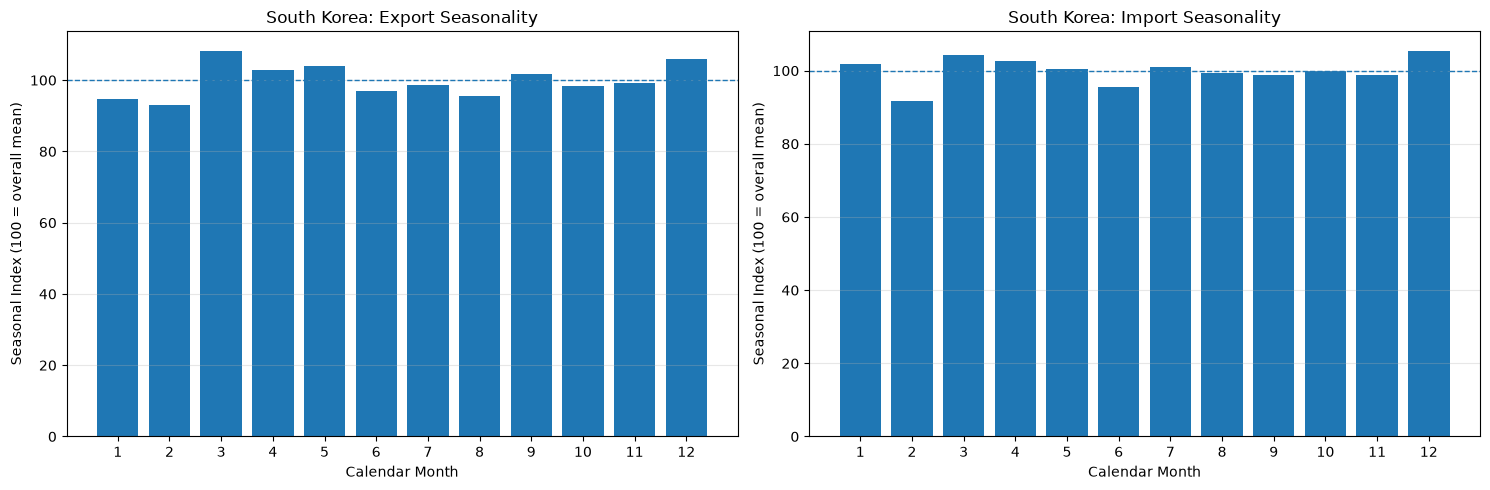

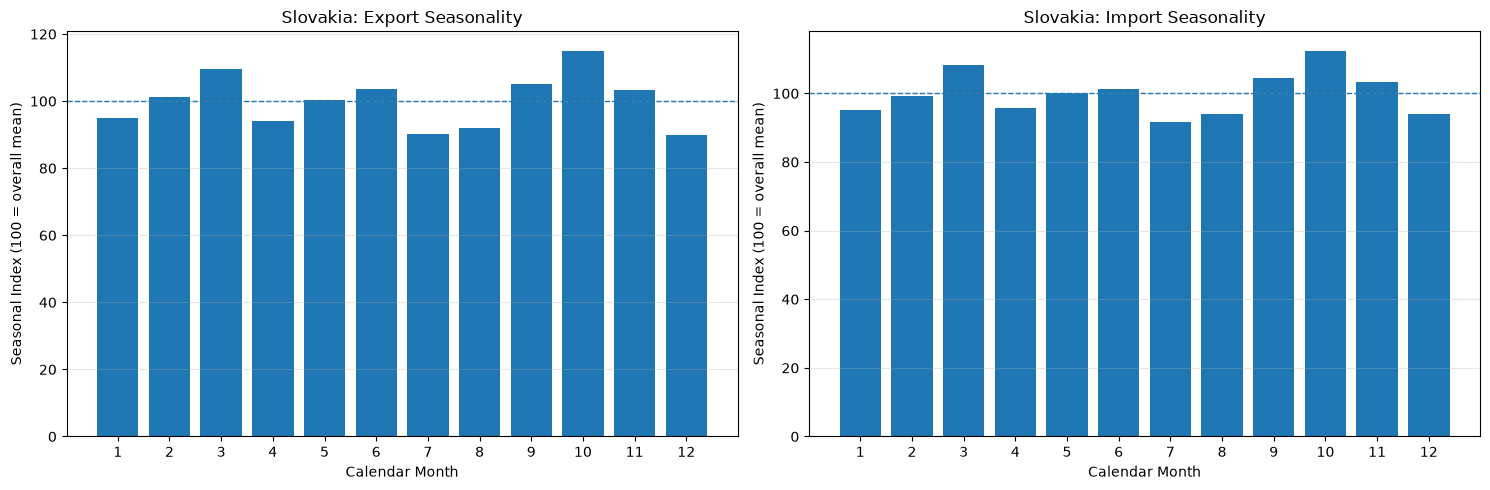

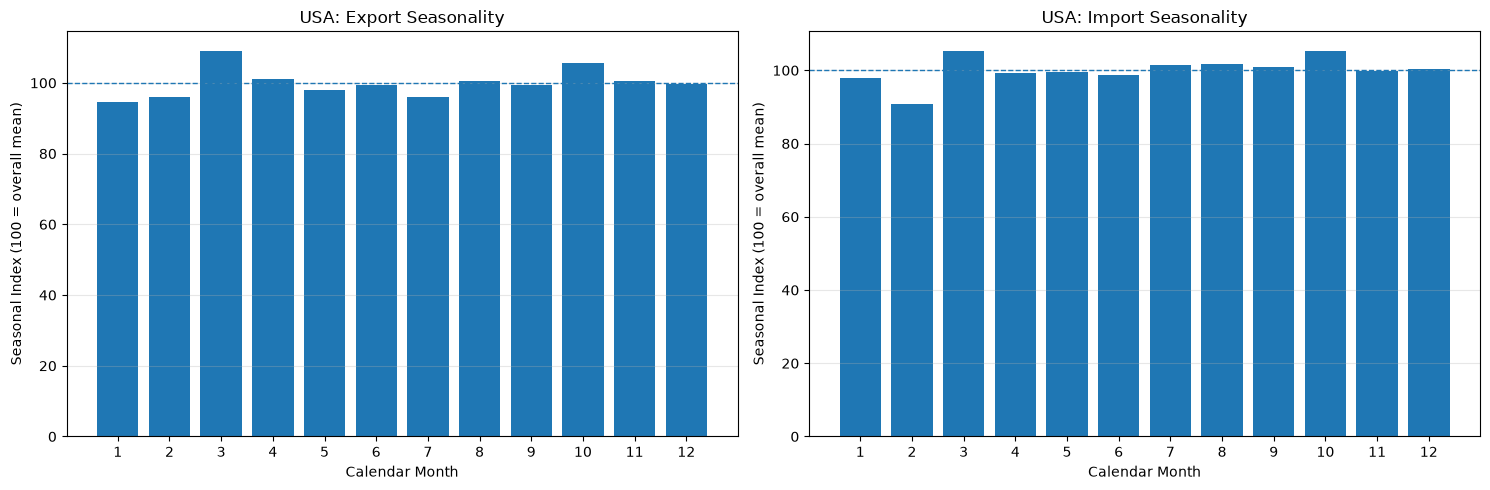

In [49]:
for country, path in completed_datasets.items():
    file_path = path.as_posix().replace("'", "''")

    monthly = con.execute(f"""
        SELECT
            Month,
            TradeFlow,
            SUM(Value) AS TotalValue
        FROM read_parquet('{file_path}')
        GROUP BY Month, TradeFlow
        ORDER BY Month
    """).df()

    monthly["Month"] = pd.to_datetime(monthly["Month"])
    monthly["CalendarMonth"] = monthly["Month"].dt.month

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    for ax, flow in zip(axes, ["export", "import"]):
        data = monthly[monthly["TradeFlow"] == flow].copy()

        # Average trade value for each calendar month.
        seasonal_profile = (
            data.groupby("CalendarMonth")["TotalValue"]
            .mean()
            .reindex(range(1, 13))
        )

        # Index relative to the overall mean; 100 represents the mean.
        seasonal_index = (
            seasonal_profile / data["TotalValue"].mean() * 100
        )

        ax.bar(
            seasonal_index.index,
            seasonal_index.values
        )
        ax.axhline(100, linewidth=1, linestyle="--")
        ax.set_xticks(range(1, 13))
        ax.set_xlabel("Calendar Month")
        ax.set_ylabel("Seasonal Index (100 = overall mean)")
        ax.set_title(f"{country}: {flow.capitalize()} Seasonality")
        ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

### 10. Autocorrelation Analysis

Examine autocorrelation and partial autocorrelation in monthly export and import series to identify temporal dependence and potential annual seasonality relevant to ARIMA and SARIMA forecasting.

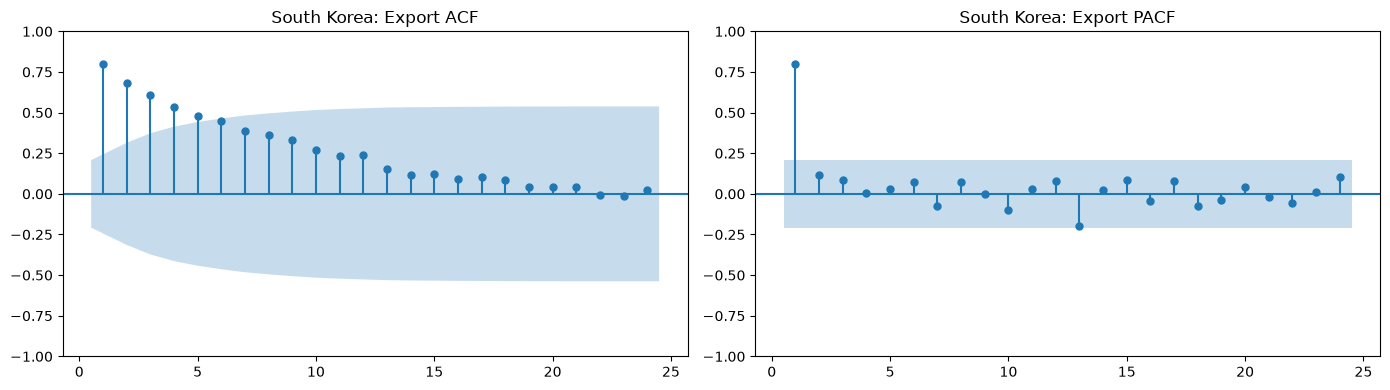

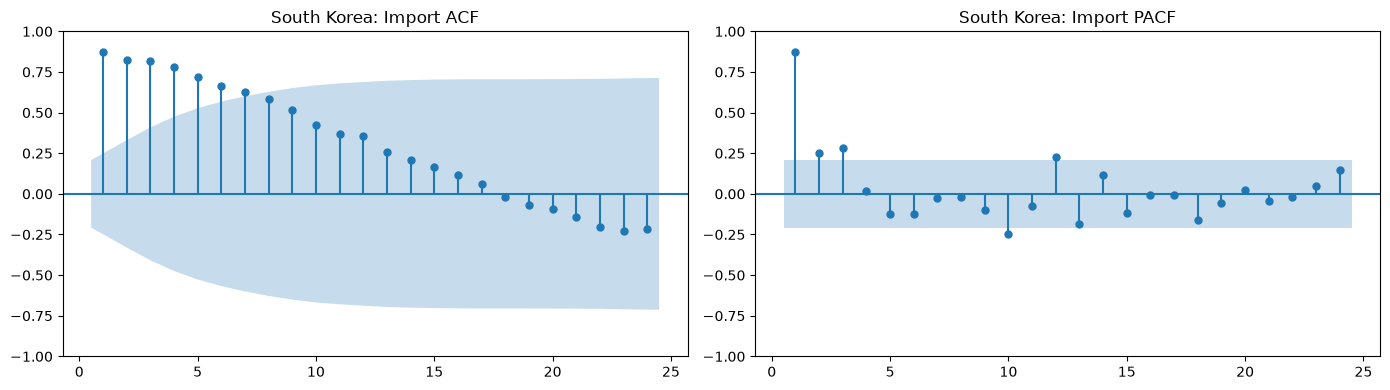

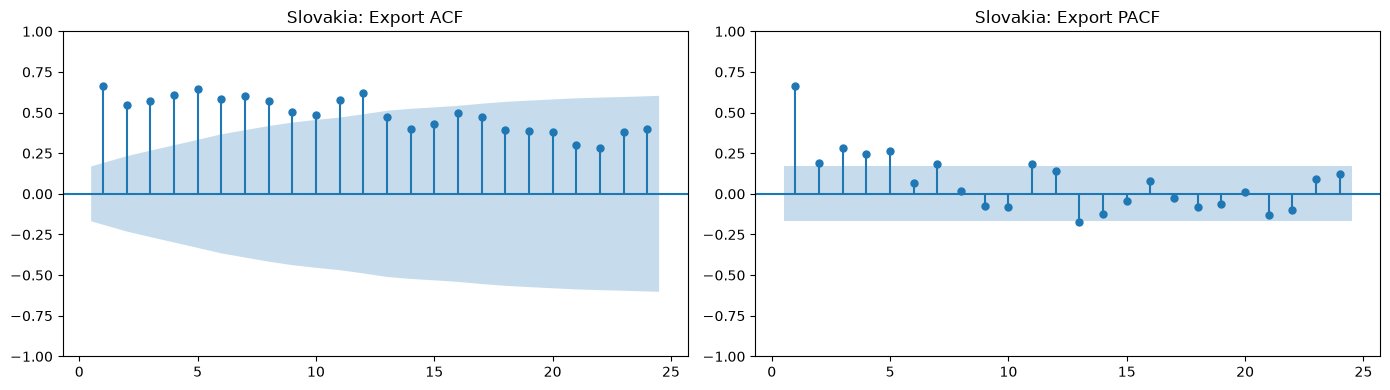

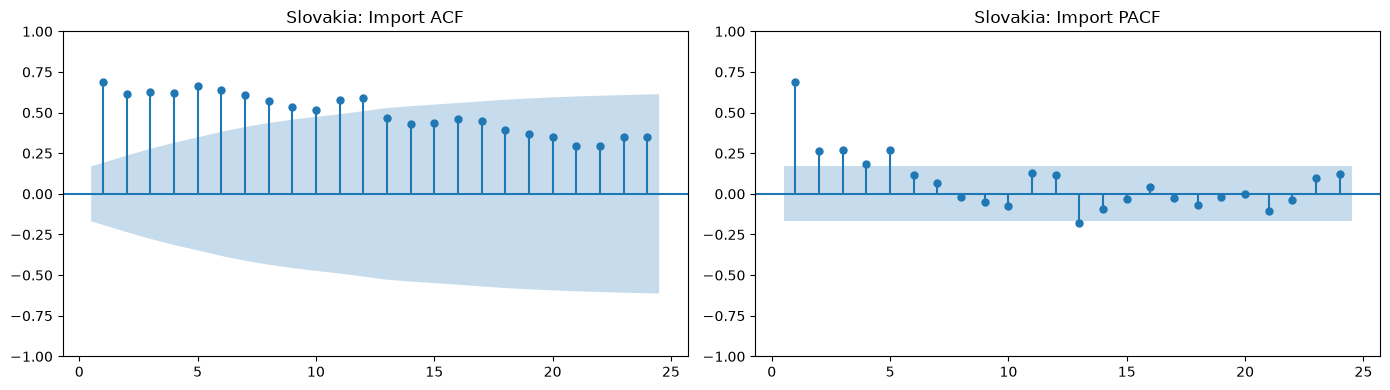

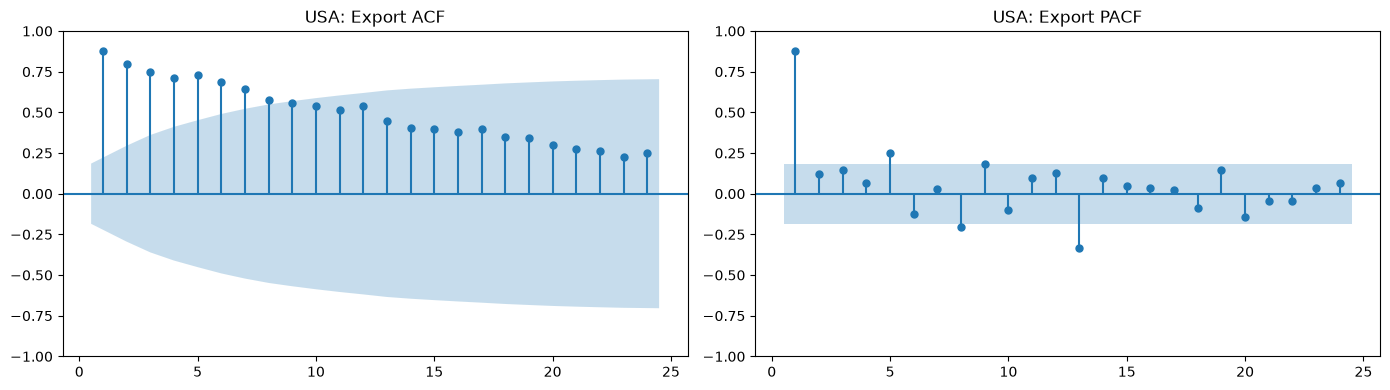

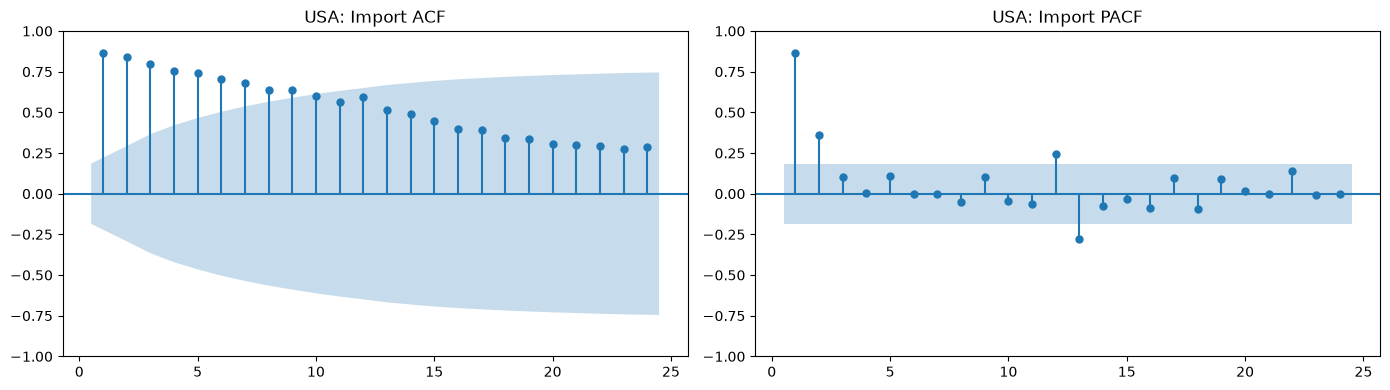

In [50]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

MAX_LAGS = 24

for country, path in completed_datasets.items():
    file_path = path.as_posix().replace("'", "''")

    monthly = con.execute(f"""
        SELECT
            Month,
            TradeFlow,
            SUM(Value) AS TotalValue
        FROM read_parquet('{file_path}')
        GROUP BY Month, TradeFlow
        ORDER BY Month
    """).df()

    for flow in ["export", "import"]:
        series = (
            monthly.loc[monthly["TradeFlow"] == flow]
            .sort_values("Month")
            .set_index("Month")["TotalValue"]
            .astype(float)
        )

        fig, axes = plt.subplots(1, 2, figsize=(14, 4))

        plot_acf(series, lags=MAX_LAGS, ax=axes[0], zero=False)
        axes[0].set_title(f"{country}: {flow.capitalize()} ACF")

        plot_pacf(
            series,
            lags=MAX_LAGS,
            ax=axes[1],
            method="ywm",
            zero=False
        )
        axes[1].set_title(f"{country}: {flow.capitalize()} PACF")

        plt.tight_layout()
        plt.show()

### 11. Trend and Stationarity Analysis

Compare the original monthly trade series with first-differenced series to assess trends and changes in level, informing whether differencing may be needed for time-series forecasting.

C:\Users\User\AppData\Local\Temp\ipykernel_23852\3672800526.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(test_series, regression="c", autolag="AIC")
C:\Users\User\AppData\Local\Temp\ipykernel_23852\3672800526.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(test_series, regression="c", autolag="AIC")
C:\Users\User\AppData\Lo

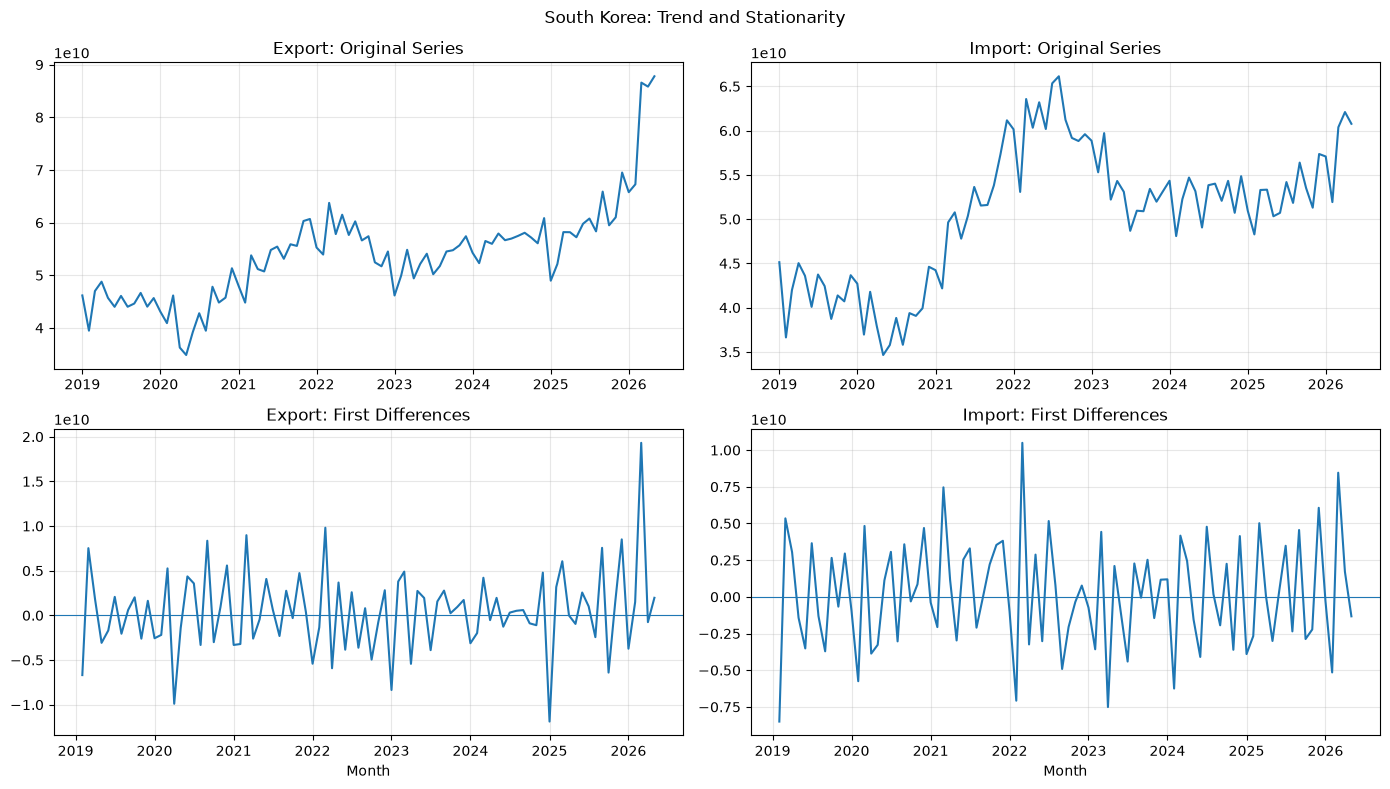

C:\Users\User\AppData\Local\Temp\ipykernel_23852\3672800526.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(test_series, regression="c", autolag="AIC")
C:\Users\User\AppData\Local\Temp\ipykernel_23852\3672800526.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(test_series, regression="c", autolag="AIC")
C:\Users\User\AppData\Lo

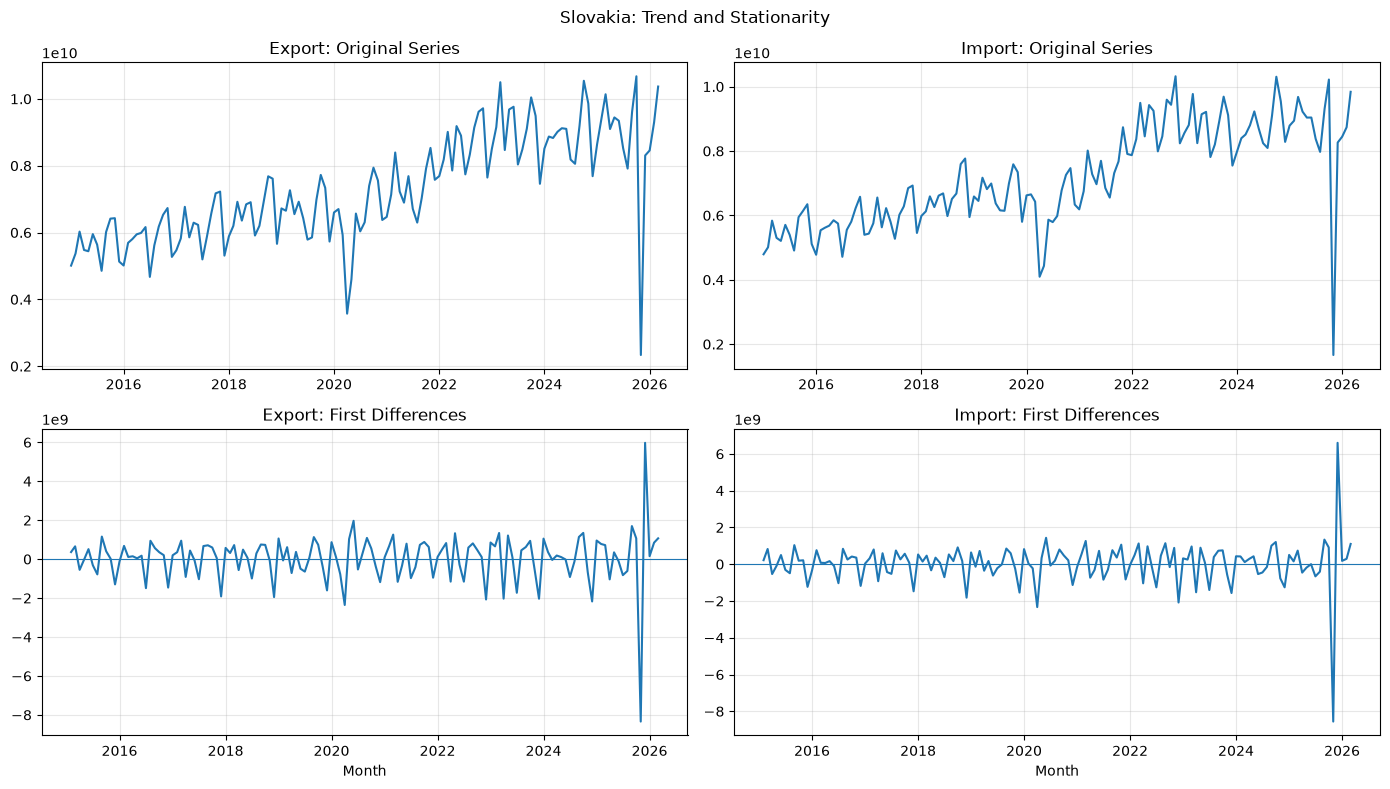

C:\Users\User\AppData\Local\Temp\ipykernel_23852\3672800526.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(test_series, regression="c", autolag="AIC")
C:\Users\User\AppData\Local\Temp\ipykernel_23852\3672800526.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(test_series, regression="c", autolag="AIC")
C:\Users\User\AppData\Lo

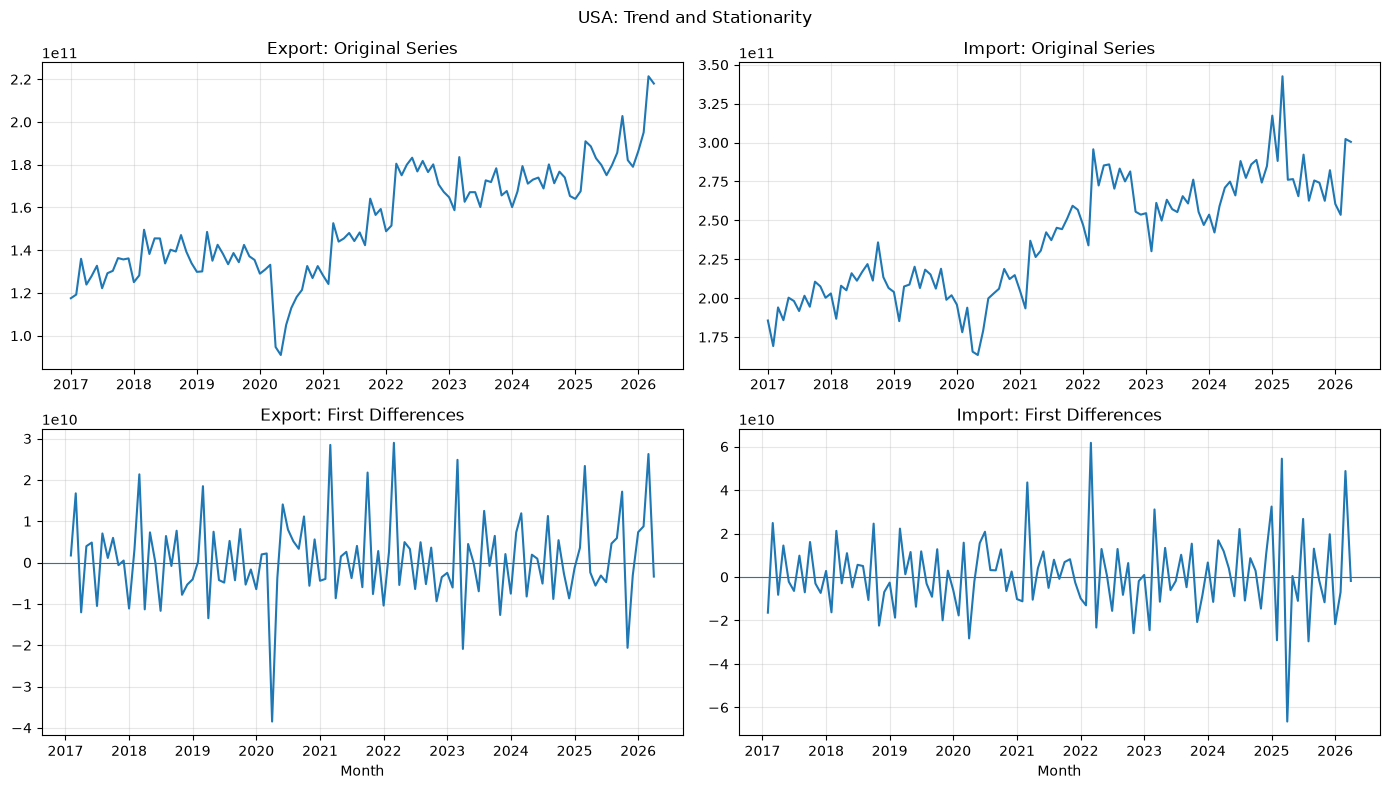

,Country,TradeFlow,Series,ADF Statistic,p-value,Used Lags,Observations,5% Critical Value,Reject Unit Root at 5%
0,South Korea,export,Original,0.2194,0.9733,12,76,-2.9004,False
1,South Korea,export,First Difference,-0.1872,0.9400,11,76,-2.9004,False
2,South Korea,import,Original,-1.4992,0.5339,11,77,-2.8999,False
3,South Korea,import,First Difference,-2.4580,0.1260,12,75,-2.9009,False
4,Slovakia,export,Original,-1.0763,0.7244,12,122,-2.8855,False
5,Slovakia,export,First Difference,-4.0579,0.0011,11,122,-2.8855,True
6,Slovakia,import,Original,-1.3444,0.6086,12,122,-2.8855,False
7,Slovakia,import,First Difference,-3.4087,0.0107,11,122,-2.8855,True
8,USA,export,Original,-0.1938,0.9393,13,98,-2.8915,False
9,USA,export,First Difference,-2.4614,0.1252,12,98,-2.8915,False


In [51]:
from statsmodels.tsa.stattools import adfuller

adf_results = []

for country, path in completed_datasets.items():
    file_path = path.as_posix().replace("'", "''")

    monthly = con.execute(f"""
        SELECT
            Month,
            TradeFlow,
            SUM(Value) AS TotalValue
        FROM read_parquet('{file_path}')
        GROUP BY Month, TradeFlow
        ORDER BY Month
    """).df()

    monthly["Month"] = pd.to_datetime(monthly["Month"])

    fig, axes = plt.subplots(2, 2, figsize=(14, 8))

    for col, flow in enumerate(["export", "import"]):
        series = (
            monthly.loc[monthly["TradeFlow"] == flow]
            .sort_values("Month")
            .set_index("Month")["TotalValue"]
            .astype(float)
        )

        # Original series
        axes[0, col].plot(series.index, series.values)
        axes[0, col].set_title(f"{flow.capitalize()}: Original Series")
        axes[0, col].grid(True, alpha=0.3)

        # First differences
        differenced = series.diff().dropna()
        axes[1, col].plot(differenced.index, differenced.values)
        axes[1, col].axhline(0, linewidth=0.8)
        axes[1, col].set_title(f"{flow.capitalize()}: First Differences")
        axes[1, col].set_xlabel("Month")
        axes[1, col].grid(True, alpha=0.3)

        # ADF test on original and first-differenced series
        for series_type, test_series in [
            ("Original", series),
            ("First Difference", differenced)
        ]:
            result = adfuller(test_series, regression="c", autolag="AIC")

            adf_results.append({
                "Country": country,
                "TradeFlow": flow,
                "Series": series_type,
                "ADF Statistic": result[0],
                "p-value": result[1],
                "Used Lags": result[2],
                "Observations": result[3],
                "5% Critical Value": result[4]["5%"],
                "Reject Unit Root at 5%": result[1] < 0.05
            })

    fig.suptitle(f"{country}: Trend and Stationarity")
    plt.tight_layout()
    plt.show()

adf_results = pd.DataFrame(adf_results)
display(adf_results.round(4))

# Exploratory Data Analysis — Final Report

## 1. Objective

The objective of this notebook was to explore the harmonized bilateral trade datasets for South Korea, Slovakia, and the USA, assess their suitability for forecasting, and identify temporal characteristics that may inform the selection of forecasting models.

The analysis examined dataset structure, data quality, aggregate export and import trends, trading partners, year-over-year growth, seasonal profiles, autocorrelation, and stationarity.

## 2. Data Sources and Input Files

The analysis used the harmonized Parquet datasets produced by the preceding preprocessing workflow:

| Country | Input file | Observation period |
|---|---|---|
| South Korea | `data/processed/korea_trade_monthly.parquet` | Jan 2019 – May 2026 |
| Slovakia | `data/processed/slovakia_trade_monthly.parquet` | Jan 2015 – Mar 2026 |
| USA | `data/processed/usa_trade_aggregated.parquet` | Jan 2017 – Apr 2026 |

All datasets share the same schema:

- `Month`: monthly observation date
- `Country1`: reporting country code
- `Country2`: trading partner country code
- `ProductCode`: HS4 product code
- `TradeFlow`: export or import
- `Value`: trade value stored as `DOUBLE`

The USA dataset had already been deduplicated and aggregated across states during preprocessing. Consequently, the three datasets are harmonized structurally, but their source definitions, historical coverage, and possible valuation conventions should not automatically be assumed identical.

## 3. Data Inspection and Quality Assessment

The initial inspection produced the following results:

| Metric | South Korea | Slovakia | USA |
|---|---:|---:|---:|
| Rows | 7,587,708 | 4,590,816 | 15,342,433 |
| Months | 89 | 135 | 112 |
| Trading partners | 250 | 235 | 231 |
| Distinct HS4 products | 1,230 | 1,234 | 1,241 |
| Trade-flow categories | 2 | 2 | 2 |

All three datasets contained the expected six columns and consistent data types.

The quality checks found:

- No missing values in the analytical columns.
- No negative trade values.
- No unexpected trade-flow labels; all values were classified as `export` or `import`.
- No invalid product codes under the applied four-digit numeric-code check.
- No duplicate analytical keys, defined by `Month`, `Country1`, `Country2`, `ProductCode`, and `TradeFlow`.

These results confirm that the processed datasets satisfy the structural and basic quality checks implemented in this notebook. They do not independently establish the correctness of every source observation or the completeness of every individual partner-product series.

## 4. Monthly Trade Trends and Aggregate Trade Flows

Monthly trade values were aggregated separately for exports and imports in each country. The resulting time series were visualized to examine changes in trade levels over the observation periods.

Aggregate exports and imports were calculated as follows:

| Country | Total exports | Total imports | Export/import ratio |
|---|---:|---:|---:|
| South Korea | 4.796 × 10¹² | 4.513 × 10¹² | 1.063 |
| Slovakia | 9.840 × 10¹¹ | 9.708 × 10¹¹ | 1.014 |
| USA | 1.720 × 10¹³ | 2.664 × 10¹³ | 0.646 |

The ratios describe the relative aggregate export and import values within each dataset. They should not be interpreted as directly comparable economic indicators without confirming that the underlying sources use comparable units, valuation conventions, and coverage.

The time-series plots provide a descriptive overview of trade movements. Identifying the causes of individual fluctuations or structural changes would require additional investigation and external evidence.

## 5. Trading Partner Analysis

The ten largest trading partners by aggregate trade value were identified separately for exports and imports in each country.

The results highlight the importance of major trading relationships:

- **South Korea:** China and the USA were the two largest export partners. China was also the largest import partner, followed by the USA and Japan.
- **Slovakia:** Germany was the largest partner for both exports and imports, followed by Czechia.
- **USA:** Canada and Mexico were the two largest export partners, while China was the largest import partner, followed by Mexico and Canada.

These rankings describe aggregate trade values across the full available observation periods. They do not establish whether partner rankings remained stable over time, and differences in observation periods should be considered when interpreting the totals.

## 6. Temporal Patterns and Year-over-Year Growth

Trends — interpretation of observed patterns
South Korea
- 2019–2020: Exports and imports decline, reaching their lowest visible levels around mid-2020.
- 2020–2022: Both flows recover substantially, reaching elevated levels in late 2021 and 2022.
- 2022–2024: Trade values fluctuate, with exports and imports generally moving within similar ranges.
- 2025–2026: Exports rise sharply, reaching approximately \(8.8\times10^{10}\) in the final month, while imports remain closer to \(6.2\times10^{10}\). This creates a noticeably wider gap between the two flows.
Key finding: The recent export surge stands out from the preceding pattern and could materially affect forecast accuracy. The final observations should be checked for data anomalies or unusual trade developments before interpreting the increase as a persistent trend.

Slovakia
- 2015–2019: Exports and imports generally increase, although both fluctuate considerably from month to month.
- 2020: Both flows experience a pronounced drop around early 2020, followed by a recovery.
- 2021–2025: The overall level rises, with monthly values often reaching higher levels than in the earlier years. Exports and imports largely move together.
- Late 2025: Both series show an exceptionally sharp one-month decline, followed by a rapid rebound. This is sufficiently unusual to warrant checking the underlying observations.
Key finding: Slovakia exhibits a clear longer-term increase alongside substantial monthly volatility. The extreme drops may influence model fitting and evaluation, so their validity should be checked before deciding whether to treat them as genuine observations or anomalies.

USA
- 2017–2019: Exports increase moderately, while imports remain considerably higher. Both fluctuate without a consistently strong upward movement.
- 2020: Exports and imports fall sharply, followed by a recovery.
- 2021–2022: Both flows rise substantially, with imports showing a particularly pronounced increase.
- 2023–2024: Exports remain comparatively stable, while imports fluctuate at a higher level.

- 2025–2026: Both series increase toward the end of the period, although imports remain well above exports.
Key finding: US imports consistently exceed exports, and the gap remains substantial throughout the period. The strong changes around 2020–2022 and the later increases suggest that a model relying only on a single linear trend may be inadequate.
Overall implication for forecasting
Across the three countries, the plots suggest changing trend levels, short-term fluctuations, and potentially influential unusual observations. This supports benchmarking simple baselines against ETS and ARIMA/SARIMA models, with machine-learning models using lagged values and calendar features as additional candidates. The plots alone do not establish the causes of the changes or prove that a structural break occurred.

### 7. Missing-Month Coverage Analysis

An additional coverage analysis was conducted to assess the completeness of individual product-level bilateral trade series. Although the datasets contain no missing values in their recorded analytical fields, many series do not have observations for every month within the reporting period. Among series with at least 36 observations, only 4.84% of Slovakia's, 38.75% of South Korea's, and 31.47% of the USA's series were fully covered according to the coverage analysis. Heatmaps of selected series illustrated that missing months vary across products and trading partners. These absent observations were interpreted as zero trade.


## 8. Forecasting Suitability and Monthly Series Characteristics

The aggregate monthly series were checked for missing months and summarized using descriptive statistics.

| Country | Flow | Observations | Missing months | Zero-value months |
|---|---|---:|---:|---:|
| South Korea | Export | 89 | 0 | 0 |
| South Korea | Import | 89 | 0 | 0 |
| Slovakia | Export | 135 | 0 | 0 |
| Slovakia | Import | 135 | 0 | 0 |
| USA | Export | 112 | 0 | 0 |
| USA | Import | 112 | 0 | 0 |

All six aggregate series have continuous monthly coverage over their respective observation periods, with no zero-valued monthly totals.

The series differ in length: Slovakia has 135 observations, the USA has 112, and South Korea has 89. This difference matters when designing chronological validation, selecting a forecast horizon, and interpreting comparisons across countries.

These checks apply to aggregate export and import totals. They do not establish that every individual bilateral partner-product series has complete observations or sufficient history for reliable forecasting.


## 9. Seasonality, Autocorrelation, and Stationarity

### 9.1 Seasonality

Seasonality — interpretation of observed patterns

South Korea
- Exports: March and December have the highest seasonal indices, at approximately 108 and 106. February and January are comparatively weaker, around 93–95.
- Imports: December is highest, at approximately 106, followed by March and April at around 103–105. February and June are weaker, at approximately 92–96.
- Comparison: Both flows show some similarities, particularly stronger March and December values, although their monthly profiles are not identical.

Key finding: South Korea shows a modest calendar-month pattern, with stronger average trade values around March and December. The differences are relatively small, so the strength and stability of seasonality should be assessed through forecasting performance.

Slovakia
- Exports: October has the highest seasonal index, approximately 115. March is also relatively strong, at around 109. July, August, and December are among the weakest months, around 90–92.
- Imports: October is highest, at approximately 112, followed by March and September. July and December are comparatively weak.
- Comparison: Exports and imports show similar monthly profiles, particularly the October peak and weaker summer/December values.

Key finding: Slovakia displays the clearest seasonal pattern of the three countries in these plots, especially the October peak. However, the large unusual movements in the trend plots may influence the monthly averages, so the pattern should not automatically be assumed stable.

USA
- Exports: March has the highest seasonal index, approximately 109, followed by October at around 105. January and February are comparatively weaker.
- Imports: March and October are the strongest months, at approximately 105. February is the weakest, around 91.
- Comparison: Export and import profiles are broadly similar, with stronger March and October values, although the variation across months is modest overall.

Key finding: US trade shows relatively mild seasonality, with March and October standing out for both flows. Most months remain close to the overall monthly average.

Overall conclusion
Country	Observed seasonal pattern
South Korea	--> Modest; stronger March and December; Test seasonal-naive and seasonal ARIMA models
Slovakia --> More pronounced; October peak; Seasonal models are particularly worth benchmarking
USA	Relatively ---> mild; stronger March and October ;Compare seasonal models against non-seasonal baselines

### 9.2 Autocorrelation — interpretation of observed patterns
The ACF plots show how strongly each series relates to its past values, while the PACF plots show the relationship at each lag after accounting for shorter lags.

South Korea
- Exports: The ACF starts high (around 0.80 at lag 1) and declines gradually, remaining positive across most of the 24 lags. The PACF has a dominant spike at lag 1, with most later lags comparatively small.
- Imports: The ACF is even more persistent, starting around 0.87 and declining gradually toward zero before becoming slightly negative at the final lags. The PACF has strong early-lag values, particularly at lags 1–3, with a few additional spikes.

Key finding: Both flows exhibit strong persistence, especially imports. The gradual ACF decay is consistent with trend or non-stationarity, which aligns with the ADF results that failed to reject the unit-root null for both original series. Differencing should be considered when fitting ARIMA models.

Slovakia
- Exports: The ACF remains strongly positive across all 24 lags, generally around 0.3–0.7, without a rapid decay. The PACF has a strong lag-1 spike and several smaller early-lag spikes.
- Imports: The pattern is similar: the ACF remains positive and substantial at longer lags, while the PACF shows a dominant lag-1 spike and some additional early-lag dependence.

Key finding: Both flows exhibit substantial temporal persistence. However, the ADF tests reject the unit-root null after first differencing for both series. This suggests that differenced specifications are worth testing, while the ACF/PACF patterns can help guide candidate ARIMA orders.

USA
- Exports: The ACF starts around 0.88 and declines slowly, remaining positive through lag 24. The PACF has a dominant lag-1 spike, with a few additional notable spikes.
- Imports: The ACF also decays gradually from a high initial value, remaining positive even at longer lags. The PACF is dominated by lag 1, with a smaller number of additional spikes.

Key finding: Both US series show strong persistence, particularly at short lags. The slow ACF decay is consistent with the ADF results for the original series, which did not reject the unit-root null.

Overall conclusion


South Korea	--> Strong persistence; ACF decays gradually; Test differencing and ARIMA-family models
Slovakia ----> High autocorrelation persists across many lags; Test differenced models and compare candidate AR/MA orders
USA	Strong ---> lag-1 dependence and gradual ACF decay ;Test differencing and lag-based forecasting models
Important limitation: These ACF/PACF plots were calculated on the original aggregate series, which may contain trends and structural changes.

### 9.3 Stationarity and the Augmented Dickey–Fuller Test

The plots compare each original trade series with its first differences. The visual patterns are consistent with the ADF test results, but the statistical conclusions should be based on the test results rather than the plots alone.

#### South Korea
Original series: Exports rise overall, with a noticeable increase in 2021–2022 and a sharp surge in early 2026. Imports rise until around 2022, then fluctuate around a relatively stable level before increasing again toward the end.

First differences: Both series fluctuate around zero, but large positive and negative movements remain, particularly in exports around 2025–2026.

Key finding: First differencing does not provide sufficient ADF evidence of stationarity for either series. Alternative specifications, such as transformations or models that account for structural changes, may be worth testing.

#### Slovakia
Original series: Both exports and imports have a clear upward trend, with recurring monthly fluctuations. The exceptionally sharp decline and rebound around late 2025 stand out in both series.

First differences: The series fluctuate around zero, although extreme changes remain around the late-2025 event.

Key finding: The ADF results support first differencing as a candidate for making both Slovak series stationary. However, the extreme late-2025 observations should be investigated because they may influence the test and model estimates.

#### USA
Original series: Exports and imports generally increase over the period, with substantial changes around 2020–2022 and further fluctuations afterward. Imports also show a pronounced spike in 2025.

First differences: Both series fluctuate around zero but exhibit large irregular movements, particularly imports.

Key finding: First differencing receives ADF support for US imports, but not for exports. Further investigation of transformations or structural changes may be useful for exports.

#### Augmented Dickey–Fuller

The Augmented Dickey–Fuller (ADF) test was applied to each original series and its first difference. The test used a constant term and selected lag lengths using the Akaike Information Criterion (AIC).

The null hypothesis is that the series contains a unit root. At the 5% significance level, the results were:

| Country | Flow | Original p-value | First-difference p-value |
|---|---|---:|---:|
| South Korea | Export | 0.9733 | 0.9400 |
| South Korea | Import | 0.5339 | 0.1260 |
| Slovakia | Export | 0.7244 | 0.0011 |
| Slovakia | Import | 0.6086 | 0.0107 |
| USA | Export | 0.9393 | 0.1252 |
| USA | Import | 0.8046 | 0.0336 |

At the 5% significance level, the test did not reject the unit-root null hypothesis for any original series.

After first differencing, the test rejected the null for both Slovakian series and US imports. It did not reject the null for South Korean exports or imports or US exports.

These findings suggest that first differencing may be useful for some series, but it does not provide sufficient evidence of stationarity for all six series. Failure to reject the null is not proof that a unit root exists, and rejection is not definitive proof of stationarity under every possible data-generating process.

Structural changes, seasonal patterns, and the relatively limited number of annual cycles may affect the diagnostics. Further model-specific residual checks and, where appropriate, seasonal differencing or transformations should be considered during model development.



## 10. Methodological Considerations and Limitations

Several limitations should guide the interpretation and use of these results:

1. **Different observation periods:** The datasets cover different numbers of months, so forecasting evaluations must respect each series' available history.
2. **Aggregate versus bilateral forecasting:** The present temporal diagnostics use national export and import totals. The target bilateral trade-flow series may exhibit different patterns and should be examined separately before finalizing the forecasting design.
3. **Source comparability:** Harmonized column names and data types do not guarantee identical trade valuation, reporting conventions, or coverage across countries.
4. **Seasonality:** Calendar-month averages are exploratory and do not establish statistically significant seasonal effects.
5. **Stationarity:** ADF results are diagnostic evidence, not a complete specification procedure. Trends, structural breaks, and seasonal dependence may require additional treatment.
6. **Forecast evaluation:** No forecasting models were fitted or compared in this EDA notebook. Conclusions about predictive performance must come from a separate, leakage-free temporal validation process.

## 11. Recommended Next Steps

The EDA supports the following next steps for the forecasting pipeline:

- Define the exact forecasting target and granularity, including whether the benchmark forecasts national totals or individual bilateral partner flows.
- Establish common chronological validation principles and a consistent forecast horizon.
- Implement naive and seasonal-naive baselines.
- Evaluate classical models such as ETS and ARIMA/SARIMA, using diagnostics to guide model specification.
- Evaluate machine-learning models such as XGBoost using lagged values and calendar features, with all features constructed using information available at forecast time.
- Compare models using consistent metrics such as MAE and sMAPE, with RMSE as an optional additional metric.
- Investigate auxiliary data only after establishing a reliable baseline, and measure whether it improves out-of-sample accuracy.
- Keep model selection, preprocessing, and hyperparameter tuning within the training and validation periods to avoid information leakage.

## 11. Conclusion

The exploratory analysis confirms that the three harmonized datasets have consistent schemas, pass the implemented basic quality checks, and provide continuous monthly coverage for their respective aggregate export and import series.

The partner analysis identifies prominent trading relationships, while seasonal profiles, autocorrelation plots, and ADF tests provide initial evidence about temporal dependence and stationarity. The ADF results show that first differencing does not produce a clear stationary-series result for every country and trade flow.

These findings provide a basis for designing the forecasting experiments, but they do not determine which model will perform best. The final choice should be based on consistent chronological validation and out-of-sample forecast accuracy, while accounting for differences in observation periods, source conventions, and the intended level of bilateral forecasting.